In [1]:
import os
import sys
import glob
import time
import zipfile
import subprocess
import unicodedata

# ==============================================================================
# 0. 필수 패키지 및 한글 폰트 자동 설정
# ==============================================================================
for pkg in ["pyproj", "scipy", "matplotlib"]:
    try:
        __import__(pkg)
    except ImportError:
        print(f"📦 [Colab 환경] 필수 라이브러리({pkg}) 설치 중...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from pyproj import Transformer
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu, hypergeom, pearsonr, spearmanr

if not any(os.path.exists(p) for p in [
    "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]):
    subprocess.run(["apt-get", "-qq", "-y", "install", "fonts-nanum"], check=False)

for fpath in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf") + [
    "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
]:
    if os.path.exists(fpath):
        fm.fontManager.addfont(fpath)

for fn in ["NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP", "Malgun Gothic", "AppleGothic"]:
    if any(fn.lower() in f.name.lower() for f in fm.fontManager.ttflist):
        plt.rcParams["font.family"] = fn
        break
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# ==============================================================================
# 1. NFD/NFC 한글 호환 스마트 파일 탐색기
# ==============================================================================
SEARCH_ROOTS = [
    "/working_dir/c_875f0ec6be5ee127/user_uploaded_files/ttl=63d/user_uploaded",
    "/content",
    "/content/data",
    "/content/drive/MyDrive",
    ".",
    "./data",
]

EXACT_FILE_MAP = {
    "정류장마스터": "서울시_정류장마스터_정보.csv",
    "승하차_인원_정보": "2026년_버스노선별_정류장별_시간대별_승하차_인원_정보(09월).csv",
    "생활인구": "[내국인]_서울_생활인구(250m)_20261009.csv",
    "주민등록": "행정안전부_지역별(행정동) 성별 연령별 주민등록 인구수_20260930.csv",
    "역사마스터": "서울시_역사마스터_정보.csv",
    "한국철도공사": "한국철도공사_역 위치 정보_20240401.csv",
    "리프트": "서울시 지하철 출입구 리프트 위치정보.csv",
    "지하도공간정보": "서울시 지하철역 연계 지하도 공간정보.csv",
    "횡단보도": "서울특별시 자치구 횡단보도 정보.csv",
    "경사도": "서울시 경사도.zip",
    "보도중심선": "국가기본도_보도중심선.zip",
    "N3A_C0390000": "N3A_C0390000.zip",
    "C_UQ164_RF": "C_UQ164_RF.zip",
    "A058_L": "A058_L_20260213.zip",
}


def norm_nfc(s):
    return unicodedata.normalize("NFC", str(s))


def find_file(keyword, required=True, ext_filter=None):
    kw_clean = norm_nfc(keyword).replace(" ", "").replace("_", "").lower()
    exact_name = EXACT_FILE_MAP.get(keyword, keyword)

    for root in SEARCH_ROOTS:
        p = os.path.join(root, exact_name)
        if os.path.exists(p):
            return p

    for root in SEARCH_ROOTS:
        if not os.path.exists(root):
            continue
        for cur_dir, dirs, files in os.walk(root):
            if cur_dir[len(root):].count(os.sep) > 3:
                dirs[:] = []
                continue
            for f in files:
                if ext_filter and not f.lower().endswith(ext_filter.lower()):
                    continue
                f_clean = norm_nfc(f).replace(" ", "").replace("_", "").lower()
                if kw_clean in f_clean:
                    return os.path.join(cur_dir, f)

    if required:
        raise FileNotFoundError(
            f"❌ 필수 파일('{exact_name}')을 찾을 수 없습니다. Colab 왼쪽 [파일(📁)] 창에 업로드되었는지 확인하세요."
        )
    return None


EXT_DIR = "/tmp/gis_extract" if os.path.exists("/tmp") else "./gis_extract"
OUT_DIR = "./output"
os.makedirs(EXT_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)


def ensure_shp_available(zip_keyword, shp_keyword, target_sub):
    existing_shp = find_file(shp_keyword, required=False, ext_filter=".shp")
    if existing_shp:
        return existing_shp

    sub_dir = os.path.join(EXT_DIR, target_sub)
    if os.path.exists(sub_dir):
        matches = glob.glob(os.path.join(sub_dir, f"**/*{shp_keyword}*.shp"), recursive=True)
        if matches:
            return matches[0]

    z_path = find_file(zip_keyword, required=False, ext_filter=".zip")
    if z_path is None:
        return None

    os.makedirs(sub_dir, exist_ok=True)
    print(f"📦 압축 해제 중: {os.path.basename(z_path)} -> {sub_dir}")
    with zipfile.ZipFile(z_path, "r") as z:
        for info in z.infolist():
            fn = info.filename
            for enc in ["cp437", "utf-8"]:
                try:
                    fn = info.filename.encode(enc).decode("euc-kr")
                    break
                except Exception:
                    pass
            tp = os.path.join(sub_dir, fn)
            if info.is_dir() or fn.endswith("/"):
                os.makedirs(tp, exist_ok=True)
            else:
                os.makedirs(os.path.dirname(tp), exist_ok=True)
                with z.open(info) as src, open(tp, "wb") as dst:
                    dst.write(src.read())

    matches = glob.glob(os.path.join(sub_dir, f"**/*{shp_keyword}*.shp"), recursive=True)
    return matches[0] if matches else None


In [3]:
# ==============================================================================
# 2. 1:5,000 수치지도 기반 3D 표고(DEM) 및 경사도 엔진
# ==============================================================================
SEOUL_TOPO_PEAKS_5179 = np.array([
    [954200, 1962100, 835.6, 5500, 14.5],
    [953900, 1955300, 342.0, 2800, 11.8],
    [952100, 1953800, 338.0, 2400, 11.2],
    [956500, 1953400, 125.0, 1600,  9.5],
    [954800, 1950400, 262.0, 2500, 10.4],
    [951200, 1938800, 632.0, 5200, 13.8],
    [956800, 1941800, 293.0, 3200,  8.5],
    [951900, 1944800, 175.0, 2600, 10.8],
    [950000, 1954600, 215.0, 2500,  9.8],
    [947400, 1956500, 209.0, 2800,  9.2],
    [952800, 1952200, 296.0, 2200, 10.5],
    [957900, 1949800, 120.0, 1800,  8.8],
    [964800, 1951800, 287.0, 2800,  9.4],
    [963500, 1961200, 508.0, 3800,  9.6],
    [961200, 1965500, 637.0, 4000, 10.2],
    [958200, 1957200, 140.0, 2300,  8.9],
    [941500, 1942500, 144.0, 2600,  7.2],
    [944500, 1939200, 320.0, 3000,  8.6],
], dtype=float)


def build_3d_terrain_engine():
    shp_p = ensure_shp_available("경사도", "N3P_F002", "서울시_경사도")
    shp_l = ensure_shp_available("경사도", "N3L_F001", "서울시_경사도")

    if shp_p and shp_l:
        try:
            import geopandas as gpd
            from shapely import get_coordinates
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "geopandas", "-q"])
            import geopandas as gpd
            from shapely import get_coordinates

        print("\n⏳ [Step 1] '서울시 경사도.zip' 감지 완료! 1:5,000 수치지도 3D IDW 보간 트리 구축 중...")
        gdf_p = gpd.read_file(shp_p, encoding="cp949").to_crs(epsg=5179)
        gdf_l = gpd.read_file(shp_l, encoding="cp949").to_crs(epsg=5179)

        p_coords = get_coordinates(gdf_p.geometry)
        p_z = gdf_p["HEIGHT"].values.astype(float)
        l_coords, l_idx = get_coordinates(gdf_l.geometry, return_index=True)
        l_z = gdf_l["HEIGHT"].values[l_idx].astype(float)

        elev_xy = np.vstack([p_coords, l_coords[::5]])
        elev_z = np.concatenate([p_z, l_z[::5]])
        elev_tree = cKDTree(elev_xy)
        print(f"  ✅ 수치지도 원본 기반 통합 3D 보간 기준점: {len(elev_xy):,}개 구축 완료!")
        return {"mode": "shapefile", "tree": elev_tree, "z": elev_z}
    else:
        print("\nℹ️ [Step 1] '서울시 경사도.zip' 미업로드 상태 -> 내장 1:5,000 수치지도 3D 제어점 모델로 작동합니다.")
        return {"mode": "builtin_model"}


def evaluate_elevation_and_slope(pts_5179, terrain_engine, sw_tree=None, sw_slope_pct=None, sw_len=None):
    if terrain_engine["mode"] == "shapefile":
        elev_tree = terrain_engine["tree"]
        elev_z = terrain_engine["z"]
        dists, idxs = elev_tree.query(pts_5179, k=6)
        weights = 1.0 / np.maximum(dists, 0.5) ** 2
        z_vals = np.sum(weights * elev_z[idxs], axis=1) / np.sum(weights, axis=1)

        dists12, idxs12 = elev_tree.query(pts_5179, k=12)
        local_dz = np.percentile(elev_z[idxs12], 85, axis=1) - np.percentile(elev_z[idxs12], 15, axis=1)
        local_dx = np.maximum(np.mean(dists12[:, 1:], axis=1) * 2.0, 20.0)
        terrain_slope_pct = np.minimum((local_dz / local_dx) * 100.0, 30.0)

        if sw_tree is not None and sw_slope_pct is not None:
            sw_ball = sw_tree.query_ball_point(pts_5179, r=100.0)
            _, sw_nearest = sw_tree.query(pts_5179, k=3)
            approach_slope, max_slope = [], []
            for i, s_idxs in enumerate(sw_ball):
                if len(s_idxs) > 0:
                    s_vals = sw_slope_pct[s_idxs]
                    w_vals = sw_len[s_idxs]
                    w_mean = np.average(s_vals, weights=w_vals)
                    approach_slope.append(max(w_mean, 0.7 * w_mean + 0.3 * terrain_slope_pct[i]))
                    max_slope.append(np.percentile(s_vals, 90))
                else:
                    s_vals = sw_slope_pct[sw_nearest[i]]
                    approach_slope.append(max(float(np.mean(s_vals)), terrain_slope_pct[i]))
                    max_slope.append(float(np.max(s_vals)))
            return np.round(z_vals, 2), np.round(approach_slope, 2), np.round(max_slope, 2)
        return np.round(z_vals, 2), np.round(terrain_slope_pct, 2), np.round(terrain_slope_pct * 1.35, 2)

    z_vals = np.full(len(pts_5179), 18.5, dtype=float)
    slope_vals = np.full(len(pts_5179), 1.35, dtype=float)
    for px, py, p_elev, p_rad, p_slope in SEOUL_TOPO_PEAKS_5179:
        dist = np.hypot(pts_5179[:, 0] - px, pts_5179[:, 1] - py)
        w = np.exp(-0.5 * (dist / (p_rad * 0.55)) ** 2)
        z_vals += (p_elev * 0.35) * w
        ring_w = np.exp(-0.5 * ((dist - p_rad * 0.45) / (p_rad * 0.38)) ** 2)
        slope_vals = np.maximum(slope_vals, 1.35 + (p_slope - 1.35) * ring_w)

    return np.round(z_vals, 2), np.round(slope_vals, 2), np.round(slope_vals * 1.35, 2)


In [4]:
# ==============================================================================
# 3. 메인 실행 파이프라인 (전처리 -> 6.1~6.5절 통계검정·민감도·3등급 -> 7.4절 탄소감축 -> 9장 시각화)
# ==============================================================================
import time

if __name__ == "__main__":
    t0 = time.time()
    TO_5179 = Transformer.from_crs("EPSG:4326", "EPSG:5179", always_xy=True)
    TO_4326 = Transformer.from_crs("EPSG:5179", "EPSG:4326", always_xy=True)
    E_MAP = {'가': 700000, '나': 800000, '다': 900000, '라': 1000000}
    N_MAP = {'가': 1300000, '나': 1400000, '다': 1500000, '라': 1600000,
             '마': 1700000, '바': 1800000, '사': 1900000, '아': 2000000}

    def decode_national_grid_250m(grid_series):
        x_5179 = np.array([E_MAP[g[0]] + int(g[2:6]) * 10 + 125.0 for g in grid_series], dtype=float)
        y_5179 = np.array([N_MAP[g[1]] + int(g[6:10]) * 10 + 125.0 for g in grid_series], dtype=float)
        lon, lat = TO_4326.transform(x_5179, y_5179)
        return x_5179, y_5179, lon, lat

    terrain_engine = build_3d_terrain_engine()

    print("\n⏳ [Step 2] 보도중심선·계단·버스전용차선 공간정보 로드 중...")
    shp_sw = ensure_shp_available("보도중심선", "TN_FTPTH_CTLN", "국가기본도_보도중심선")
    shp_stairs = ensure_shp_available("N3A_C0390000", "N3A_C0390000", "N3A_C0390000")
    shp_lanes = ensure_shp_available("A058_L", "A058_L", "A058_L_20260213")

    sw_tree, sw_slope_pct, sw_len = None, None, None
    stair_tree, lane_tree = None, None

    if shp_sw and terrain_engine["mode"] == "shapefile":
        import geopandas as gpd
        from shapely import get_coordinates
        bbox_5179 = (934000, 1935000, 973000, 1967000)
        gdf_sw = gpd.read_file(shp_sw, bbox=bbox_5179, encoding="cp949")
        sw_coords, sw_idx = get_coordinates(gdf_sw.geometry, return_index=True)
        _, first_pos = np.unique(sw_idx, return_index=True)
        last_pos = np.append(first_pos[1:] - 1, len(sw_coords) - 1)
        p_start, p_end = sw_coords[first_pos], sw_coords[last_pos]
        seg_len = gdf_sw.geometry.length.values
        valid_mask = seg_len > 1.0
        p_start, p_end, sw_len = p_start[valid_mask], p_end[valid_mask], seg_len[valid_mask]
        mid_pts = 0.5 * (p_start + p_end)
        z_start, _, _ = evaluate_elevation_and_slope(p_start, terrain_engine)
        z_end, _, _ = evaluate_elevation_and_slope(p_end, terrain_engine)
        sw_slope_pct = np.minimum(np.abs(z_end - z_start) / np.maximum(sw_len, 1.0), 0.35) * 100.0
        sw_tree = cKDTree(mid_pts)
        print(f"  ✅ 보도중심선 {len(sw_len):,}개 링크 종단경사 산출 완료")

    if shp_stairs:
        import geopandas as gpd
        gdf_stairs = gpd.read_file(shp_stairs, encoding="cp949").to_crs(epsg=5179)
        stair_pts = np.column_stack([gdf_stairs.geometry.centroid.x.values, gdf_stairs.geometry.centroid.y.values])
        stair_tree = cKDTree(stair_pts)
        print(f"  ✅ 계단 공간정보(N3A_C0390000): {len(stair_pts):,}개 폴리곤 로드 완료")

    if shp_lanes:
        import geopandas as gpd
        from shapely import get_coordinates
        gdf_lanes = gpd.read_file(shp_lanes, encoding="cp949").to_crs(epsg=5179)
        lane_tree = cKDTree(get_coordinates(gdf_lanes.geometry))
        print(f"  ✅ 버스전용차선(A058_L): {len(gdf_lanes):,}개 링크 로드 완료")

📦 압축 해제 중: 서울시 경사도.zip -> /tmp/gis_extract/서울시_경사도

⏳ [Step 1] '서울시 경사도.zip' 감지 완료! 1:5,000 수치지도 3D IDW 보간 트리 구축 중...
  ✅ 수치지도 원본 기반 통합 3D 보간 기준점: 2,273,230개 구축 완료!

⏳ [Step 2] 보도중심선·계단·버스전용차선 공간정보 로드 중...
📦 압축 해제 중: 국가기본도_보도중심선.zip -> /tmp/gis_extract/국가기본도_보도중심선
📦 압축 해제 중: N3A_C0390000.zip -> /tmp/gis_extract/N3A_C0390000
📦 압축 해제 중: A058_L_20260213.zip -> /tmp/gis_extract/A058_L_20260213
  ✅ 보도중심선 58,531개 링크 종단경사 산출 완료
  ✅ 계단 공간정보(N3A_C0390000): 39,411개 폴리곤 로드 완료
  ✅ 버스전용차선(A058_L): 3,249개 링크 로드 완료


In [5]:
# --------------------------------------------------------------------------
# [Step 3] 버스정류장(11,362개 / 시내 7,110개), 2026.09 승하차, 지하철, 횡단보도 결합
# --------------------------------------------------------------------------
print("\n⏳ [Step 3] 버스정류장·지하철·횡단보도 및 2026년 9월 시간대별 승하차 빅데이터 결합 중...")
bus_raw = pd.read_csv(find_file("정류장마스터"), encoding="cp949")
bus_valid = bus_raw[~bus_raw["정류장_유형"].isin(["가상정류장", "선착장"])].copy().reset_index(drop=True)
bx, by = TO_5179.transform(bus_valid["경도"].values, bus_valid["위도"].values)
bus_valid["x_5179"], bus_valid["y_5179"] = bx, by

rid_path = find_file("승하차_인원_정보", required=False) or find_file("승하차", required=False)
rid_raw = None
if rid_path:
    rid_raw = pd.read_csv(rid_path, encoding="cp949", low_memory=False)
    rid_raw["id_str"] = rid_raw["표준버스정류장ID"].astype(str).str.strip()
    board_cols = [f"{h:02d}시승차총승객수" if (f"{h:02d}시승차총승객수" in rid_raw.columns) else f"{h}시승차총승객수" for h in range(24)]
    alight_cols = [f"{h:02d}시하차총승객수" if (f"{h:02d}시하차총승객수" in rid_raw.columns) else f"{h}시하차총승객수" for h in range(24)]
    for c in board_cols + alight_cols:
        rid_raw[c] = pd.to_numeric(rid_raw[c], errors="coerce").fillna(0)

    rid_raw["월간_승차합계"] = rid_raw[board_cols].sum(axis=1)
    rid_raw["월간_하차합계"] = rid_raw[alight_cols].sum(axis=1)
    rid_raw["월간_승하차합계"] = rid_raw["월간_승차합계"] + rid_raw["월간_하차합계"]

    peak_hours = [7, 8, 9, 17, 18, 19]
    midday_hours = [10, 11, 12, 13, 14, 15]
    dawn_hours = [4, 5, 6]
    rid_raw["출퇴근_승하차"] = rid_raw[[f"{h}시승차총승객수" for h in peak_hours] + [f"{h}시하차총승객수" for h in peak_hours]].sum(axis=1)
    rid_raw["낮시간_승하차"] = rid_raw[[f"{h}시승차총승객수" for h in midday_hours] + [f"{h}시하차총승객수" for h in midday_hours]].sum(axis=1)
    rid_raw["새벽_승하차"] = rid_raw[[f"{h}시승차총승객수" for h in dawn_hours] + [f"{h}시하차총승객수" for h in dawn_hours]].sum(axis=1)

    stop_rid = rid_raw.groupby("id_str", as_index=False).agg(
        경유_노선수=("노선번호", "nunique"),
        월간_승차총승객수=("월간_승차합계", "sum"),
        월간_하차총승객수=("월간_하차합계", "sum"),
        월간_승하차총승객수=("월간_승하차합계", "sum"),
        출퇴근_승하차승객수=("출퇴근_승하차", "sum"),
        낮시간_승하차승객수=("낮시간_승하차", "sum"),
        새벽_승하차승객수=("새벽_승하차", "sum"),
    )
    stop_rid["일평균_승차인원"] = stop_rid["월간_승차총승객수"] / 30.0
    stop_rid["일평균_하차인원"] = stop_rid["월간_하차총승객수"] / 30.0
    stop_rid["일평균_승하차인원"] = stop_rid["월간_승하차총승객수"] / 30.0
    stop_rid["출퇴근_승하차비율"] = np.where(stop_rid["월간_승하차총승객수"] > 0, stop_rid["출퇴근_승하차승객수"] / stop_rid["월간_승하차총승객수"], 0.0)
    stop_rid["낮시간_승하차비율"] = np.where(stop_rid["월간_승하차총승객수"] > 0, stop_rid["낮시간_승하차승객수"] / stop_rid["월간_승하차총승객수"], 0.0)
    bus_valid["id_str"] = bus_valid["정류장_ID"].astype(str).str.strip()
    bus_valid = pd.merge(bus_valid, stop_rid, on="id_str", how="left")
    for col in ["경유_노선수", "월간_승차총승객수", "월간_하차총승객수", "월간_승하차총승객수",
                "일평균_승차인원", "일평균_하차인원", "일평균_승하차인원",
                "출퇴근_승하차비율", "낮시간_승하차비율", "새벽_승하차승객수"]:
        bus_valid[col] = bus_valid[col].fillna(0)
else:
    for col, def_v in [("경유_노선수", 3), ("월간_승하차총승객수", 15000), ("일평균_승하차인원", 500.0),
                       ("출퇴근_승하차비율", 0.32), ("낮시간_승하차비율", 0.24)]:
        bus_valid[col] = def_v

b_pts = bus_valid[["x_5179", "y_5179"]].values
b_z, b_slope, b_max_slope = evaluate_elevation_and_slope(b_pts, terrain_engine, sw_tree, sw_slope_pct, sw_len)
bus_valid["표고_m"] = b_z
bus_valid["접근보도_경사도_pct"] = b_slope
bus_valid["접근보도_최대경사도_pct"] = b_max_slope
bus_valid["반경100m_계단수"] = stair_tree.query_ball_point(b_pts, r=100.0, return_length=True) if stair_tree else np.where(b_slope >= 4.5, 4, 1)
bus_valid["전용차선_거리_m"] = lane_tree.query(b_pts, k=1)[0] if lane_tree else 50.0

sub_raw = pd.read_csv(find_file("역사마스터"), encoding="cp949")
sub_seoul = sub_raw[(sub_raw["위도"].between(37.425, 37.705)) & (sub_raw["경도"].between(126.760, 127.190))].copy().reset_index(drop=True)
sx, sy = TO_5179.transform(sub_seoul["경도"].values, sub_seoul["위도"].values)
sub_seoul["x_5179"], sub_seoul["y_5179"] = sx, sy

korail_path = find_file("한국철도공사", required=False)
if korail_path:
    korail_raw = pd.read_csv(korail_path, encoding="cp949")
    korail_seoul = korail_raw[(korail_raw["위도"].between(37.425, 37.705)) & (korail_raw["경도"].between(126.760, 127.190))].copy().reset_index(drop=True)
    kx, ky = TO_5179.transform(korail_seoul["경도"].values, korail_seoul["위도"].values)
    korail_seoul["x_5179"], korail_seoul["y_5179"] = kx, ky
    korail_coords = korail_seoul[["x_5179", "y_5179"]].values
else:
    korail_coords = np.empty((0, 2))

lift_raw = pd.read_csv(find_file("리프트"), encoding="cp949")
wkt_coords = lift_raw["노드 WKT"].str.extract(r"POINT\(([0-9.]+)\s+([0-9.]+)\)")
lift_raw["경도"], lift_raw["위도"] = wkt_coords[0].astype(float), wkt_coords[1].astype(float)
lax, ly = TO_5179.transform(lift_raw["경도"].values, lift_raw["위도"].values)
lift_raw["x_5179"], lift_raw["y_5179"] = lax, ly

cw_raw = pd.read_csv(find_file("횡단보도"), encoding="cp949").dropna(subset=["경도", "위도"]).copy().reset_index(drop=True)
cx, cy = TO_5179.transform(cw_raw["경도"].values, cw_raw["위도"].values)
cw_raw["x_5179"], cw_raw["y_5179"] = cx, cy

bus_brt = bus_valid[bus_valid["정류장_유형"].isin(["중앙차로", "가로변시간", "가로변전일"])].copy().reset_index(drop=True)
bus_city = bus_valid[bus_valid["정류장_유형"] != "마을버스"].copy().reset_index(drop=True)


⏳ [Step 3] 버스정류장·지하철·횡단보도 및 2026년 9월 시간대별 승하차 빅데이터 결합 중...


In [6]:
# --------------------------------------------------------------------------
# [Step 4] 250m 격자(8,566개) 정규화 + 행정동 주민등록 인구 배분 + 층 A·B·C 거리 산출
# --------------------------------------------------------------------------
print("\n⏳ [Step 4] 250m 격자(8,566개) 정규화 및 층 A(2D)·층 B(보행망)·층 C(3D 경사) 산출 중...")
pop_raw = pd.read_csv(find_file("생활인구"), encoding="cp949", low_memory=False)
pop_raw["생활인구합계_num"] = pd.to_numeric(pop_raw["생활인구합계"].replace("*", np.nan), errors="coerce").fillna(2.0)
senior_cols = ['남자 65~69세', '남자 70세 이상', '여자 65~69세', '여자 70세 이상']
young_cols = ['남자 20~24세', '남자 25~29세', '남자 30~34세', '남자 35~39세',
              '여자 20~24세', '여자 25~29세', '여자 30~34세', '여자 35~39세']
for c in senior_cols + young_cols:
    pop_raw[c + "_num"] = pd.to_numeric(pop_raw[c].replace("*", np.nan), errors="coerce")
    pop_raw[c + "_imp"] = pop_raw[c + "_num"].fillna(1.5)
pop_raw["고령생활인구_관측"] = pop_raw[[c + "_num" for c in senior_cols]].fillna(0).sum(axis=1)
pop_raw["고령생활인구_보정"] = np.minimum(pop_raw[[c + "_imp" for c in senior_cols]].sum(axis=1), pop_raw["생활인구합계_num"])
pop_raw["청년생활인구_보정"] = np.minimum(pop_raw[[c + "_imp" for c in young_cols]].sum(axis=1), pop_raw["생활인구합계_num"])

pair_all = pop_raw.groupby(["250M격자", "행정동코드"], as_index=False).agg(
    일평균_총생활인구=("생활인구합계_num", lambda s: s.sum() / 24.0),
    일평균_고령생활인구_관측=("고령생활인구_관측", lambda s: s.sum() / 24.0),
    일평균_고령생활인구_보정=("고령생활인구_보정", lambda s: s.sum() / 24.0),
    일평균_청년생활인구_보정=("청년생활인구_보정", lambda s: s.sum() / 24.0),
)
dawn_df = pop_raw[pop_raw["시간"].isin([0, 1, 2, 3, 4, 5])]
pair_dawn = dawn_df.groupby(["250M격자", "행정동코드"], as_index=False).agg(새벽_총생활인구=("생활인구합계_num", lambda s: s.sum() / 6.0))
pair_df = pd.merge(pair_all, pair_dawn, on=["250M격자", "행정동코드"], how="left")
pair_df["새벽_총생활인구"] = pair_df["새벽_총생활인구"].fillna(pair_df["일평균_총생활인구"])

reg_raw = pd.read_csv(find_file("주민등록"), encoding="cp949", low_memory=False)
reg_dong = reg_raw[(reg_raw["시도명"] == "서울특별시") & (reg_raw["행정기관코드"] % 100000 != 0)].copy()
reg_dong["행정동코드"] = (reg_dong["행정기관코드"] // 100).astype(int)
m_65 = [f"{i}세남자" for i in range(65, 110)] + ["110세이상 남자"]
f_65 = [f"{i}세여자" for i in range(65, 110)] + ["110세이상 여자"]
m_2030 = [f"{i}세남자" for i in range(20, 40)]
f_2030 = [f"{i}세여자" for i in range(20, 40)]
for c in m_65 + f_65 + m_2030 + f_2030 + ["계"]:
    if reg_dong[c].dtype == object:
        reg_dong[c] = reg_dong[c].astype(str).str.replace(",", "").astype(float)
reg_dong["동_주민등록_총인구"] = reg_dong["계"]
reg_dong["동_주민등록_고령인구"] = reg_dong[m_65 + f_65].sum(axis=1)
reg_dong["동_주민등록_2030인구"] = reg_dong[m_2030 + f_2030].sum(axis=1)

pair_df = pd.merge(
    pair_df,
    reg_dong[["행정동코드", "시군구명", "읍면동명", "동_주민등록_총인구", "동_주민등록_고령인구", "동_주민등록_2030인구"]],
    on="행정동코드", how="left"
)
dong_dawn_sum = pair_df.groupby("행정동코드")["새벽_총생활인구"].transform("sum")
pair_df["동내_새벽비중"] = np.where(dong_dawn_sum > 0, pair_df["새벽_총생활인구"] / dong_dawn_sum, 0.0)
pair_df["추정_주민총인구"] = pair_df["동_주민등록_총인구"] * pair_df["동내_새벽비중"]
pair_df["추정_주민고령인구"] = pair_df["동_주민등록_고령인구"] * pair_df["동내_새벽비중"]
pair_df["추정_주민2030인구"] = pair_df["동_주민등록_2030인구"] * pair_df["동내_새벽비중"]

pair_sorted = pair_df.sort_values(by=["250M격자", "새벽_총생활인구"], ascending=[True, False])
rep_dong = pair_sorted.drop_duplicates(subset=["250M격자"])[["250M격자", "행정동코드", "시군구명", "읍면동명"]]
grid_df = pair_df.groupby("250M격자", as_index=False).agg(
    일평균_총생활인구=("일평균_총생활인구", "sum"),
    일평균_고령생활인구_관측=("일평균_고령생활인구_관측", "sum"),
    일평균_고령생활인구_보정=("일평균_고령생활인구_보정", "sum"),
    일평균_청년생활인구_보정=("일평균_청년생활인구_보정", "sum"),
    새벽_총생활인구=("새벽_총생활인구", "sum"),
    격자_추정_주민총인구=("추정_주민총인구", "sum"),
    격자_추정_주민고령인구=("추정_주민고령인구", "sum"),
    격자_추정_주민2030인구=("추정_주민2030인구", "sum"),
)
grid_df = pd.merge(rep_dong, grid_df, on="250M격자", how="inner")
x_5179, y_5179, lon, lat = decode_national_grid_250m(grid_df["250M격자"])
grid_df["x_5179"], grid_df["y_5179"], grid_df["경도"], grid_df["위도"] = x_5179, y_5179, lon, lat
grid_df["고령인구_비율"] = np.where(grid_df["격자_추정_주민총인구"] > 0, grid_df["격자_추정_주민고령인구"] / grid_df["격자_추정_주민총인구"], 0.0)

sub_all_coords = np.vstack([
    sub_seoul[["x_5179", "y_5179"]].values,
    korail_coords,
    lift_raw[["x_5179", "y_5179"]].values
])
art_coords = np.vstack([sub_all_coords, bus_brt[["x_5179", "y_5179"]].values])
art_z, _, _ = evaluate_elevation_and_slope(art_coords, terrain_engine)

art_tree = cKDTree(art_coords)
sub_tree = cKDTree(sub_all_coords)
brt_tree = cKDTree(bus_brt[["x_5179", "y_5179"]].values)
bus_tree = cKDTree(bus_valid[["x_5179", "y_5179"]].values)
cw_tree = cKDTree(cw_raw[["x_5179", "y_5179"]].values)

g_pts = grid_df[["x_5179", "y_5179"]].values
g_z, g_terrain_slope, _ = evaluate_elevation_and_slope(g_pts, terrain_engine)
grid_df["표고_m"] = g_z
grid_df["dist_art_2d_m"], nearest_art_idx = art_tree.query(g_pts, k=1)
grid_df["dist_subway_2d_m"], _ = sub_tree.query(g_pts, k=1)
grid_df["dist_brt_2d_m"], _ = brt_tree.query(g_pts, k=1)
grid_df["dist_any_bus_2d_m"], _ = bus_tree.query(g_pts, k=1)

grid_cw_cnt = cw_tree.query_ball_point(g_pts, r=250.0, return_length=True)
grid_sw_cnt = sw_tree.query_ball_point(g_pts, r=250.0, return_length=True) if sw_tree else np.maximum(grid_cw_cnt * 2, 5)
grid_stair_cnt = stair_tree.query_ball_point(g_pts, r=250.0, return_length=True) if stair_tree else np.where(g_terrain_slope >= 5.0, 5, 1)

target_art_z = art_z[nearest_art_idx]
direct_dz = np.abs(grid_df["표고_m"].values - target_art_z)
direct_slope_pct = np.minimum((direct_dz / np.maximum(grid_df["dist_art_2d_m"].values, 50.0)) * 100.0, 35.0)

if sw_tree is not None and sw_slope_pct is not None:
    _, sw_near_g = sw_tree.query(g_pts, k=5)
    g_sw_slope_pct = np.mean(sw_slope_pct[sw_near_g], axis=1)
    grid_df["격자_경사도_pct"] = np.round(np.maximum(0.5 * g_sw_slope_pct + 0.5 * g_terrain_slope, direct_slope_pct), 2)
else:
    grid_df["격자_경사도_pct"] = np.round(np.maximum(g_terrain_slope, direct_slope_pct), 2)

grid_df["반경250m_보도링크수"] = grid_sw_cnt
grid_df["반경250m_계단수"] = grid_stair_cnt
grid_df["반경250m_횡단보도수"] = grid_cw_cnt

base_detour = np.where(grid_sw_cnt >= 30, 1.24, np.where(grid_sw_cnt >= 10, 1.30, np.where(grid_sw_cnt >= 1, 1.38, 1.46)))
stair_detour_add = np.minimum(grid_stair_cnt * 0.008, 0.12)
cw_detour_red = np.where(grid_cw_cnt >= 15, -0.03, 0.0)
detour_factor = np.clip(base_detour + stair_detour_add + cw_detour_red, 1.20, 1.60)

grid_df["보행망_우회계수"] = np.round(detour_factor, 3)
grid_df["dist_art_walk_2d_m"] = np.round(grid_df["dist_art_2d_m"] * detour_factor, 1)

# [4.5절 & 6.5절(1)] 3종 학술 경사 보정식 (Tobler 1993 / Wood et al. 2023 / Minetti et al. 2002) 및 보행속도 시나리오 산출
S_grid = grid_df["격자_경사도_pct"].values / 100.0
stair_penalty = 1.0 + np.minimum(grid_stair_cnt * 0.004, 0.15)

# 1) 기본식: Tobler (1993)
W_0_tobler = 6.0 * np.exp(-3.5 * 0.05)
W_S_tobler = 6.0 * np.exp(-3.5 * np.abs(S_grid + 0.05))
grid_df["tobler_보정계수"] = np.round((W_0_tobler / W_S_tobler) * stair_penalty, 3)
grid_df["dist_art_3d_tobler_m"] = np.round(grid_df["dist_art_walk_2d_m"] * grid_df["tobler_보정계수"], 1)

# 2) 대안식 A: Wood et al. (2023, arXiv:2303.16065) 포장도로 보행속도 함수
theta_deg = np.degrees(np.arctan(S_grid))
v_0_wood = np.exp(1.580)
v_theta_wood = np.exp(1.580 - 0.00726 * theta_deg - 0.00218 * (theta_deg ** 2))
r_wood = (v_0_wood / np.maximum(v_theta_wood, 0.2)) * stair_penalty
grid_df["dist_art_3d_wood_m"] = np.round(grid_df["dist_art_walk_2d_m"] * r_wood, 1)

# 3) 대안식 B: Minetti et al. (2002) 대사에너지 소비량 5차 다항식 Cr(i)/Cr(0)
i_s = np.clip(S_grid, 0.0, 0.45)
cr_0 = 2.80
cr_s = 280.5 * (i_s ** 5) - 58.7 * (i_s ** 4) - 76.8 * (i_s ** 3) + 51.9 * (i_s ** 2) + 19.6 * i_s + 2.5
r_minetti = np.maximum(cr_s / cr_0, 1.0) * stair_penalty
grid_df["dist_art_3d_minetti_m"] = np.round(grid_df["dist_art_walk_2d_m"] * r_minetti, 1)

# 4~6) 보행속도 시나리오 (일반 성인 1.29 m/s 기준 대비 고령 평균 1.13 / 경찰청 매뉴얼 1.00 / 고령 하위15% 0.85 m/s)
grid_df["dist_art_3d_senior_avg_m"] = np.round(grid_df["dist_art_3d_tobler_m" ] * (1.29 / 1.13), 1)
grid_df["dist_art_3d_manual_100_m"] = np.round(grid_df["dist_art_3d_tobler_m" ] * (1.29 / 1.00), 1)
grid_df["dist_art_3d_senior_low15_m"] = np.round(grid_df["dist_art_3d_tobler_m" ] * (1.29 / 0.85), 1)



⏳ [Step 4] 250m 격자(8,566개) 정규화 및 층 A(2D)·층 B(보행망)·층 C(3D 경사) 산출 중...


In [7]:
# --------------------------------------------------------------------------
# [Step 5] 시내버스 정류장(7,110개) 3등급 분류 & 탄소 감축량 & 2D 단순 기준 비교
# --------------------------------------------------------------------------
print("\n⏳ [Step 5] 시내버스 정류장(7,110개) 3등급 분류 및 온실가스 감축 잠재량 산출 중...")
c_pts = bus_city[["x_5179", "y_5179"]].values
c_tree = cKDTree(c_pts)
dists_k10, idxs_k10 = c_tree.query(c_pts, k=10)
bus_city["최근접_정류장_거리_m"] = np.round(dists_k10[:, 1], 1)

diff_name_dist, diff_name_id = [], []
for i in range(len(bus_city)):
    my_name = bus_city.iloc[i]["정류장_명칭"]
    found_d = dists_k10[i, 1]
    found_id = bus_city.iloc[idxs_k10[i, 1]]["정류장_ID"]
    for k_idx in range(1, 10):
        cand_row = bus_city.iloc[idxs_k10[i, k_idx]]
        if cand_row["정류장_명칭"] != my_name:
            found_d = dists_k10[i, k_idx]
            found_id = cand_row["정류장_ID"]
            break
    diff_name_dist.append(found_d)
    diff_name_id.append(found_id)

bus_city["전후_정류장_거리_m"] = np.round(diff_name_dist, 1)
bus_city["전후_최근접_정류장_ID"] = diff_name_id
bus_city["지하철_거리_m"], _ = sub_tree.query(c_pts, k=1)
bus_city["지하철_거리_m"] = np.round(bus_city["지하철_거리_m"], 1)
bus_city["역세권_200m_여부"] = bus_city["지하철_거리_m"] <= 200.0
bus_city["반경100m_횡단보도수"] = cw_tree.query_ball_point(c_pts, r=100.0, return_length=True)

S_stop = bus_city["접근보도_경사도_pct"].values / 100.0
bus_city["보행저항지수_Tobler"] = np.round((6.0 * np.exp(-3.5 * 0.05)) / (6.0 * np.exp(-3.5 * np.abs(S_stop + 0.05))), 3)
bus_city["전후_정류장_3D체감거리_m"] = np.round(bus_city["전후_정류장_거리_m"] * bus_city["보행저항지수_Tobler"], 1)

g_tree = cKDTree(g_pts)
nearby_g = g_tree.query_ball_point(c_pts, r=300.0)
_, nearest_g_idx = g_tree.query(c_pts, k=1)

tot_p, sen_p, yng_p, liv_p, liv_sen_p, gu_l, dong_l = [], [], [], [], [], [], []
for i, g_idxs in enumerate(nearby_g):
    if not g_idxs:
        g_idxs = [nearest_g_idx[i]]
    sub_g = grid_df.iloc[g_idxs]
    tot_p.append(sub_g["격자_추정_주민총인구"].sum())
    sen_p.append(sub_g["격자_추정_주민고령인구"].sum())
    yng_p.append(sub_g["격자_추정_주민2030인구"].sum())
    liv_p.append(sub_g["일평균_총생활인구"].sum())
    liv_sen_p.append(sub_g["일평균_고령생활인구_보정"].sum())
    gu_l.append(grid_df.iloc[nearest_g_idx[i]]["시군구명"])
    dong_l.append(grid_df.iloc[nearest_g_idx[i]]["읍면동명"])

bus_city["시군구명"], bus_city["읍면동명"] = gu_l, dong_l
bus_city["배후300m_주민총인구"] = np.round(tot_p, 1)
bus_city["배후300m_주민고령인구"] = np.round(sen_p, 1)
bus_city["배후300m_주민2030인구"] = np.round(yng_p, 1)
bus_city["배후300m_일평균생활인구"] = np.round(liv_p, 1)
bus_city["배후300m_고령생활인구"] = np.round(liv_sen_p, 1)
bus_city["배후_주민고령비율"] = np.where(bus_city["배후300m_주민총인구"] > 0, bus_city["배후300m_주민고령인구"] / bus_city["배후300m_주민총인구"], 0.0)
bus_city["배후_주민2030비율"] = np.where(bus_city["배후300m_주민총인구"] > 0, bus_city["배후300m_주민2030인구"] / bus_city["배후300m_주민총인구"], 0.0)

sen_q75 = bus_city["배후_주민고령비율"].quantile(0.75)
yng_q50 = bus_city["배후_주민2030비율"].quantile(0.50)
valid_rid_mask = bus_city["일평균_승하차인원"] >= 50
midday_q75 = bus_city.loc[valid_rid_mask, "낮시간_승하차비율"].quantile(0.75) if valid_rid_mask.any() else 0.30

def assign_3d_grade(row):
    slope_high = (row["접근보도_경사도_pct"] >= 5.56) or (row["접근보도_경사도_pct"] >= 4.0 and row["반경100m_계단수"] >= 3)
    senior_high = (row["배후_주민고령비율"] >= sen_q75) or (row["일평균_승하차인원"] >= 50 and row["낮시간_승하차비율"] >= midday_q75)
    spacing_wide = row["전후_정류장_거리_m"] > 300.0
    if slope_high or senior_high or spacing_wide:
        return "1등급: 보존 (약자 방어·3D경사·단절 방지)"
    elif (row["전후_정류장_거리_m"] <= 300.0) and row["역세권_200m_여부"] and ((row["배후_주민2030비율"] >= yng_q50) or (row["출퇴근_승하차비율"] >= 0.35)):
        return "2등급: 통폐합 후보 (역세권·탄소 감축)"
    else:
        return "3등급: 현행 유지 (풍선효과 방지)"

bus_city["통폐합_3등급_3D"] = bus_city.apply(assign_3d_grade, axis=1)

# [4.8절 & 7.4절] 온실가스(CO2) 감축량 3종 시나리오 산출 (보수적 하한 / 기준 / 적극적 상한)
routes_eff = np.maximum(bus_city["경유_노선수"], 1)
is_grade2 = bus_city["통폐합_3등급_3D"].str.startswith("2등급")
bus_city["연간_탄소감축_하한_tCO2"] = np.where(is_grade2, np.round(routes_eff * 60 * 365 * 0.12 / 1000.0, 2), 0.0)
bus_city["연간_탄소감축잠재량_tCO2"] = np.where(is_grade2, np.round(routes_eff * 85 * 365 * 0.18 / 1000.0, 2), 0.0)
bus_city["연간_탄소감축_상한_tCO2"] = np.where(is_grade2, np.round(routes_eff * 100 * 365 * 0.25 / 1000.0, 2), 0.0)

# CSV 결과 저장
grid_out = os.path.join(OUT_DIR, "seoul_250m_grid_3d_result_8566.csv")
bus_out = os.path.join(OUT_DIR, "seoul_bus_stop_3d_3grade_7110.csv")
grid_df.to_csv(grid_out, index=False, encoding="utf-8-sig")
bus_city.to_csv(bus_out, index=False, encoding="utf-8-sig")


⏳ [Step 5] 시내버스 정류장(7,110개) 3등급 분류 및 온실가스 감축 잠재량 산출 중...


In [8]:
# ==========================================================================
# [보고서 6.1절 출력] 대중교통 사각지대(ART)의 2D 대 3D 규모 비교표
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.1절] 대중교통 사각지대(ART)의 2D(층 A) vs 보행망(층 B) vs 3D 경사(층 C) 규모 비교")
print("=" * 90)
tot_g = len(grid_df)
tot_pop_all = grid_df["격자_추정_주민총인구"].sum()
tot_sen_all = grid_df["격자_추정_주민고령인구"].sum()

for r in [400, 600, 800, 1000]:
    la = grid_df[grid_df["dist_art_2d_m"] > r]
    lb = grid_df[grid_df["dist_art_walk_2d_m"] > r]
    lc = grid_df[grid_df["dist_art_3d_tobler_m"] > r]
    hid = grid_df[(grid_df["dist_art_2d_m"] <= r) & (grid_df["dist_art_3d_tobler_m"] > r)]
    print(f"▶ 반경 {r:4d}m | "
          f"층A(2D직선): {len(la):4,d}개({len(la)/tot_g*100:5.2f}%, {len(la)*0.0625:6.2f}km²) 고령 {la["격자_추정_주민고령인구"].sum():9,.0f}명({la["격자_추정_주민고령인구"].sum()/tot_sen_all*100:5.2f}%) | "
          f"층B(보행망): {len(lb):4,d}개 고령 {lb["격자_추정_주민고령인구"].sum():9,.0f}명 | "
          f"층C(3D경사): {len(lc):4,d}개({len(lc)/tot_g*100:5.2f}%, {len(lc)*0.0625:6.2f}km²) 고령 {lc["격자_추정_주민고령인구"].sum():9,.0f}명({lc["격자_추정_주민고령인구"].sum()/tot_sen_all*100:5.2f}%) | "
          f"숨은사각(A≤{r}<C): {len(hid):4,d}개(고령 {hid["격자_추정_주민고령인구"].sum():8,.0f}명)")


📊 [보고서 6.1절] 대중교통 사각지대(ART)의 2D(층 A) vs 보행망(층 B) vs 3D 경사(층 C) 규모 비교
▶ 반경  400m | 층A(2D직선): 5,039개(58.83%, 314.94km²) 고령   925,784명(47.09%) | 층B(보행망): 6,240개 고령 1,252,691명 | 층C(3D경사): 6,700개(78.22%, 418.75km²) 고령 1,385,056명(70.45%) | 숨은사각(A≤400<C): 1,661개(고령  459,272명)
▶ 반경  600m | 층A(2D직선): 3,297개(38.49%, 206.06km²) 고령   469,559명(23.89%) | 층B(보행망): 4,707개 고령   827,274명 | 층C(3D경사): 5,483개(64.01%, 342.69km²) 고령 1,027,346명(52.26%) | 숨은사각(A≤600<C): 2,186개(고령  557,787명)
▶ 반경  800m | 층A(2D직선): 2,173개(25.37%, 135.81km²) 고령   235,351명(11.97%) | 층B(보행망): 3,500개 고령   508,777명 | 층C(3D경사): 4,423개(51.63%, 276.44km²) 고령   736,967명(37.49%) | 숨은사각(A≤800<C): 2,250개(고령  501,616명)
▶ 반경 1000m | 층A(2D직선): 1,496개(17.46%,  93.50km²) 고령   130,524명( 6.64%) | 층B(보행망): 2,626개 고령   312,449명 | 층C(3D경사): 3,577개(41.76%, 223.56km²) 고령   514,088명(26.15%) | 숨은사각(A≤1000<C): 2,081개(고령  383,564명)


In [9]:
# ==========================================================================
# [보고서 6.2절 출력] '3D 숨은 사각지대(A≤800m & C>800m)' 자치구별 분포 표
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.2절] 반경 800m 기준 '3D 숨은 사각지대' 상위 자치구 분포")
print("=" * 90)
grid_df["숨은사각_800m"] = (grid_df["dist_art_2d_m"] <= 800.0) & (grid_df["dist_art_3d_tobler_m"] > 800.0)
gu_summary = grid_df.groupby("시군구명", as_index=False).agg(
    전체격자수=("250M격자", "count"),
    숨은사각_격자수=("숨은사각_800m", "sum"),
    자치구_평균경사도=("격자_경사도_pct", "mean"),
)
gu_hid_sen = grid_df[grid_df["숨은사각_800m"]].groupby("시군구명", as_index=False)["격자_추정_주민고령인구"].sum().rename(
    columns={"격자_추정_주민고령인구": "숨은사각_고령인구"}
)
gu_summary = pd.merge(gu_summary, gu_hid_sen, on="시군구명", how="left").fillna(0)
gu_summary["숨은사각_비율_pct"] = gu_summary["숨은사각_격자수"] / gu_summary["전체격자수"] * 100.0
gu_summary = gu_summary.sort_values("숨은사각_고령인구", ascending=False).reset_index(drop=True)

for rank_i, row in gu_summary.head(10).iterrows():
    print(f"  {rank_i+1:2d}위 | {row['시군구명']:5s} | 전체 {int(row['전체격자수']):3d}개 중 숨은사각 {int(row['숨은사각_격자수']):3d}개 ({row['숨은사각_비율_pct']:4.1f}%) | "
          f"숨은사각 고령인구: {row['숨은사각_고령인구']:8,.0f}명 | 평균경사도: {row['자치구_평균경사도']:4.2f}%")


📊 [보고서 6.2절] 반경 800m 기준 '3D 숨은 사각지대' 상위 자치구 분포
   1위 | 성북구   | 전체 354개 중 숨은사각 123개 (34.7%) | 숨은사각 고령인구:   37,037명 | 평균경사도: 9.21%
   2위 | 구로구   | 전체 325개 중 숨은사각 111개 (34.2%) | 숨은사각 고령인구:   30,856명 | 평균경사도: 4.48%
   3위 | 동작구   | 전체 263개 중 숨은사각 100개 (38.0%) | 숨은사각 고령인구:   28,965명 | 평균경사도: 7.74%
   4위 | 은평구   | 전체 387개 중 숨은사각  96개 (24.8%) | 숨은사각 고령인구:   28,287명 | 평균경사도: 8.35%
   5위 | 관악구   | 전체 355개 중 숨은사각 100개 (28.2%) | 숨은사각 고령인구:   27,880명 | 평균경사도: 9.69%
   6위 | 노원구   | 전체 443개 중 숨은사각 108개 (24.4%) | 숨은사각 고령인구:   27,024명 | 평균경사도: 5.31%
   7위 | 양천구   | 전체 285개 중 숨은사각  77개 (27.0%) | 숨은사각 고령인구:   26,895명 | 평균경사도: 4.07%
   8위 | 송파구   | 전체 514개 중 숨은사각 135개 (26.3%) | 숨은사각 고령인구:   24,156명 | 평균경사도: 2.24%
   9위 | 강서구   | 전체 568개 중 숨은사각 122개 (21.5%) | 숨은사각 고령인구:   23,457명 | 평균경사도: 3.02%
  10위 | 중랑구   | 전체 270개 중 숨은사각  75개 (27.8%) | 숨은사각 고령인구:   22,135명 | 평균경사도: 5.16%


In [10]:
# ==========================================================================
# [보고서 6.3절 출력] Mann-Whitney U 비모수 검정 (3D 숨은 사각지대 vs 3D 접근 가능 지역)
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.3절] 3D 숨은 사각지대 vs 3D 접근 가능 격자 Mann-Whitney U 비모수 검정 (양측)")
print("=" * 90)
grp_hidden = grid_df[(grid_df["dist_art_2d_m"] <= 800.0) & (grid_df["dist_art_3d_tobler_m"] > 800.0)]
grp_access = grid_df[grid_df["dist_art_3d_tobler_m"] <= 800.0]
print(f"• 비교 집단 규모: 3D 숨은 사각지대 n = {len(grp_hidden):,}개 격자 vs 3D 접근 가능 지역 n = {len(grp_access):,}개 격자")

mw_vars = [
    ("격자 표고 (m)", "표고_m", False),
    ("격자 경사도 (%)", "격자_경사도_pct", False),
    ("반경 250m 내 계단 수 (개)", "반경250m_계단수", False),
    ("반경 250m 내 횡단보도 수 (개)", "반경250m_횡단보도수", False),
    ("65세 이상 고령인구 비율 (%)", "고령인구_비율", True),
]
for label_nm, col_nm, is_ratio in mw_vars:
    v1 = grp_hidden[col_nm].dropna().values * (100.0 if is_ratio else 1.0)
    v2 = grp_access[col_nm].dropna().values * (100.0 if is_ratio else 1.0)
    u_stat, p_val = mannwhitneyu(v1, v2, alternative="two-sided")
    sig = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else "ns"))
    print(f"  - {label_nm:24s} | 숨은사각 중앙값 {np.median(v1):6.2f} (평균 {np.mean(v1):6.2f}) vs "
          f"접근가능 중앙값 {np.median(v2):6.2f} (평균 {np.mean(v2):6.2f}) | U = {u_stat:,.0f}, p = {p_val:.2e} ({sig})")

# 자치구 단위 상관분석 (4.4절 2항)
r_p, p_p = pearsonr(gu_summary["자치구_평균경사도"], gu_summary["숨은사각_고령인구"])
r_s, p_s = spearmanr(gu_summary["자치구_평균경사도"], gu_summary["숨은사각_고령인구"])
print(f"• 자치구 평균경사도 vs 숨은사각 고령인구 상관계수: Pearson r = {r_p:.3f} (p={p_p:.4f}), Spearman rho = {r_s:.3f} (p={p_s:.4f})")


📊 [보고서 6.3절] 3D 숨은 사각지대 vs 3D 접근 가능 격자 Mann-Whitney U 비모수 검정 (양측)
• 비교 집단 규모: 3D 숨은 사각지대 n = 2,250개 격자 vs 3D 접근 가능 지역 n = 4,143개 격자
  - 격자 표고 (m)                | 숨은사각 중앙값  35.30 (평균  45.09) vs 접근가능 중앙값  20.20 (평균  25.12) | U = 6,382,072, p = 9.83e-132 (***)
  - 격자 경사도 (%)               | 숨은사각 중앙값   5.75 (평균   7.33) vs 접근가능 중앙값   1.98 (평균   3.17) | U = 6,841,205, p = 3.80e-210 (***)
  - 반경 250m 내 계단 수 (개)       | 숨은사각 중앙값  14.00 (평균  18.89) vs 접근가능 중앙값   9.00 (평균  13.09) | U = 5,561,777, p = 1.84e-37 (***)
  - 반경 250m 내 횡단보도 수 (개)     | 숨은사각 중앙값   9.00 (평균  11.14) vs 접근가능 중앙값  20.00 (평균  21.10) | U = 2,422,488, p = 1.30e-221 (***)
  - 65세 이상 고령인구 비율 (%)       | 숨은사각 중앙값  21.42 (평균  21.68) vs 접근가능 중앙값  20.60 (평균  20.92) | U = 5,123,524, p = 5.22e-11 (***)
• 자치구 평균경사도 vs 숨은사각 고령인구 상관계수: Pearson r = 0.140 (p=0.5036), Spearman rho = 0.112 (p=0.5930)


In [11]:
# ==========================================================================
# [보고서 6.4절 출력] 현장 보행 인프라(지하철 리프트 83개소·고원식 횡단보도 40,281개소) 운영 실태
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.4절] 현장 보행 인프라(지하철 출입구 리프트·횡단보도 무장애 설비) 전수 집계")
print("=" * 90)
if "시군구명" in lift_raw.columns:
    lift_gu = lift_raw["시군구명"].value_counts()
    top3_lift_sum = lift_gu.head(3).sum()
    print(f"• 지하철 출입구 휠체어 리프트 (총 {len(lift_raw)}개소): 상위 3개 구({', '.join([f'{k} {v}개' for k, v in lift_gu.head(3).items()])})에 "
          f"{top3_lift_sum}개소({top3_lift_sum/len(lift_raw)*100:.1f}%) 집중")

print(f"• 서울시 자치구 횡단보도 전수 모수: {len(cw_raw):,}개소")
for infra_label, kw_col in [("보행등", "보행등"), ("음향신호기", "음향신호기"), ("고원식(무단차)", "고원식")]:
    matched_cols = [c for c in cw_raw.columns if kw_col in c]
    if matched_cols:
        col_c = matched_cols[0]
        s_val = cw_raw[col_c].astype(str).str.strip().str.upper()
        installed_mask = s_val.isin(["Y", "1", "1.0", "있음", "설치", "O", "TRUE"]) | (pd.to_numeric(cw_raw[col_c], errors="coerce").fillna(0) > 0)
        tot_rate = installed_mask.mean() * 100.0
        if "시군구명" in cw_raw.columns or "자치구명" in cw_raw.columns:
            gu_col = "시군구명" if "시군구명" in cw_raw.columns else "자치구명"
            gu_rates = cw_raw.assign(_inst=installed_mask).groupby(gu_col)["_inst"].mean() * 100.0
            print(f"  - 횡단보도 [{infra_label:12s}] 설치율: 전체 평균 {tot_rate:5.2f}% (자치구별 최저 {gu_rates.min():4.1f}% ~ 최고 {gu_rates.max():4.1f}%)")
        else:
            print(f"  - 횡단보도 [{infra_label:12s}] 설치율: 전체 평균 {tot_rate:5.2f}%")


📊 [보고서 6.4절] 현장 보행 인프라(지하철 출입구 리프트·횡단보도 무장애 설비) 전수 집계
• 지하철 출입구 휠체어 리프트 (총 83개소): 상위 3개 구(강남구 22개, 종로구 16개, 노원구 12개)에 50개소(60.2%) 집중
• 서울시 자치구 횡단보도 전수 모수: 40,281개소
  - 횡단보도 [보행등         ] 설치율: 전체 평균 33.63% (자치구별 최저 21.8% ~ 최고 41.2%)
  - 횡단보도 [음향신호기       ] 설치율: 전체 평균 28.67% (자치구별 최저 20.5% ~ 최고 36.3%)
  - 횡단보도 [고원식(무단차)    ] 설치율: 전체 평균  5.15% (자치구별 최저  0.5% ~ 최고 12.3%)


In [12]:
# ==========================================================================
# [보고서 6.5절 (1) 출력] 경사 보정식 및 보행속도 6종 시나리오 민감도 분석
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.5절 (1)] 경사 보정식(Tobler / Wood 2023 / Minetti 2002) 및 보행속도 6종 시나리오 민감도 분석")
print("=" * 90)
scenarios_6 = [
    ("시나리오 1 (기본 모형: Tobler 1993, 1.29m/s)", "dist_art_3d_tobler_m"),
    ("시나리오 2 (포장도로 대안식: Wood et al. 2023, 1.29m/s)", "dist_art_3d_wood_m"),
    ("시나리오 3 (대사에너지 대안식: Minetti et al. 2002, 1.29m/s)", "dist_art_3d_minetti_m"),
    ("시나리오 4 (고령 평균속도: Tobler 1993, 1.13m/s)", "dist_art_3d_senior_avg_m"),
    ("시나리오 5 (신호매뉴얼 기준: Tobler 1993, 1.00m/s)", "dist_art_3d_manual_100_m"),
    ("시나리오 6 (고령 취약 하위15%: Tobler 1993, 0.85m/s)", "dist_art_3d_senior_low15_m"),
]
for sc_name, sc_col in scenarios_6:
    blk = grid_df[grid_df[sc_col] > 800.0]
    hid_sc = grid_df[(grid_df["dist_art_2d_m"] <= 800.0) & (grid_df[sc_col] > 800.0)]
    print(f"  • {sc_name:50s} | 사각 격자: {len(blk):4,d}개({len(blk)/tot_g*100:4.1f}%) | "
          f"사각 고령인구: {blk['격자_추정_주민고령인구'].sum():9,.0f}명({blk['격자_추정_주민고령인구'].sum()/tot_sen_all*100:4.1f}%) | "
          f"숨은사각: {len(hid_sc):4,d}개(고령 {hid_sc['격자_추정_주민고령인구'].sum():8,.0f}명)")


📊 [보고서 6.5절 (1)] 경사 보정식(Tobler / Wood 2023 / Minetti 2002) 및 보행속도 6종 시나리오 민감도 분석
  • 시나리오 1 (기본 모형: Tobler 1993, 1.29m/s)               | 사각 격자: 4,423개(51.6%) | 사각 고령인구:   736,967명(37.5%) | 숨은사각: 2,250개(고령  501,616명)
  • 시나리오 2 (포장도로 대안식: Wood et al. 2023, 1.29m/s)       | 사각 격자: 3,975개(46.4%) | 사각 고령인구:   618,427명(31.5%) | 숨은사각: 1,802개(고령  383,076명)
  • 시나리오 3 (대사에너지 대안식: Minetti et al. 2002, 1.29m/s)   | 사각 격자: 4,586개(53.5%) | 사각 고령인구:   769,378명(39.1%) | 숨은사각: 2,413개(고령  534,027명)
  • 시나리오 4 (고령 평균속도: Tobler 1993, 1.13m/s)             | 사각 격자: 4,908개(57.3%) | 사각 고령인구:   863,316명(43.9%) | 숨은사각: 2,735개(고령  627,965명)
  • 시나리오 5 (신호매뉴얼 기준: Tobler 1993, 1.00m/s)            | 사각 격자: 5,379개(62.8%) | 사각 고령인구:   998,251명(50.8%) | 숨은사각: 3,206개(고령  762,900명)
  • 시나리오 6 (고령 취약 하위15%: Tobler 1993, 0.85m/s)         | 사각 격자: 5,935개(69.3%) | 사각 고령인구: 1,159,924명(59.0%) | 숨은사각: 3,762개(고령  924,573명)


In [13]:
# ==========================================================================
# [보고서 6.5절 (2) 출력] 시내버스 7,110개 3등급 분류 & 기존 2D 단순 기준 초기하분포 검정
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 6.5절 (2)] 시내버스 정류장(7,110개) 3등급 분류 및 기존 2D 단순 기준과의 초기하분포(Hypergeometric) 검정")
print("=" * 90)
for g_label in [
    "1등급: 보존 (약자 방어·3D경사·단절 방지)",
    "2등급: 통폐합 후보 (역세권·탄소 감축)",
    "3등급: 현행 유지 (풍선효과 방지)"
]:
    sub = bus_city[bus_city["통폐합_3등급_3D"] == g_label]
    print(f"• {g_label:38s}: {len(sub):4,d}개 ({len(sub)/len(bus_city)*100:5.2f}%) | "
          f"평균경사 {sub["접근보도_경사도_pct"].mean():4.2f}% | "
          f"전후간격 {sub["전후_정류장_거리_m"].mean():5.1f}m (3D체감 {sub["전후_정류장_3D체감거리_m"].mean():5.1f}m) | "
          f"일평균승하차 {sub["일평균_승하차인원"].mean():6.1f}명 | "
          f"배후고령 {sub["배후_주민고령비율"].mean()*100:4.1f}% / 청년 {sub["배후_주민2030비율"].mean()*100:4.1f}%")

# 기존 2D 단순 기준: 전후 정류장 2D 간격이 짧고(<=300m 우선) 일평균 승하차 인원이 적은 하위 K개 추출
N_total = len(bus_city)
mask_our_grade2 = bus_city["통폐합_3등급_3D"].str.startswith("2등급")
mask_our_grade1 = bus_city["통폐합_3등급_3D"].str.startswith("1등급")
K_target = int(mask_our_grade2.sum())

bus_city["_2d_cand_rank"] = np.where(bus_city["전후_정류장_거리_m"] <= 300.0, 0, 1)
naive_2d_idx = bus_city.sort_values(
    by=["_2d_cand_rank", "일평균_승하차인원", "전후_정류장_거리_m"],
    ascending=[True, True, True]
).head(K_target).index

mask_naive_2d = bus_city.index.isin(naive_2d_idx)
overlap_cnt = int((mask_our_grade2 & mask_naive_2d).sum())
expected_overlap = K_target * K_target / float(N_total)
# 초기하분포 유의확률 P(X >= overlap_cnt)
p_hyper = float(hypergeom.sf(overlap_cnt - 1, N_total, K_target, K_target))
misclassified_grade1_cnt = int((mask_our_grade1 & mask_naive_2d).sum())
misclassified_grade1_pct = (misclassified_grade1_cnt / float(K_target)) * 100.0 if K_target > 0 else 0.0

saved_by_3d_mask = (
    ((bus_city["접근보도_경사도_pct"] >= 5.56) | ((bus_city["접근보도_경사도_pct"] >= 4.0) & (bus_city["반경100m_계단수"] >= 3)))
    & (bus_city["전후_정류장_거리_m"] <= 300.0)
)
saved_by_3d_cnt = int(saved_by_3d_mask.sum())

print("\n[초기하분포(Hypergeometric Distribution) 교차 검증 결과]")
print(f"  1) 전체 모수 N = {N_total:,}개 중 본 모델 2등급(통폐합 후보) K = {K_target:,}개 추출")
print(f"  2) 본 모델 2등급({K_target}개)과 기존 2D 단순 기준({K_target}개)의 실제 겹침 수: {overlap_cnt}개 ({overlap_cnt/K_target*100:.1f}%)")
print(f"  3) 무작위 추출 시 이론적 기대 겹침 수 E[X] = K²/N: {expected_overlap:.1f}개 ({expected_overlap/K_target*100:.1f}%)")
print(f"  4) 초기하분포 검정 유의확률 P(겹침 ≥ {overlap_cnt}): P = {p_hyper:.4f}")
print(f"  5) 기존 2D 단순 기준({K_target}개)이 잘못 폐쇄 대상으로 지목한 '1등급(필수 보존)' 정류장: {misclassified_grade1_cnt}개 ({misclassified_grade1_pct:.1f}%)")
print(f"  6) 전후 간격 300m 이내이나 순수 '3D 급경사·계단' 기준으로 구제된 언덕 정류장: {saved_by_3d_cnt:,}개 ({saved_by_3d_cnt/N_total*100:.1f}%) ")


📊 [보고서 6.5절 (2)] 시내버스 정류장(7,110개) 3등급 분류 및 기존 2D 단순 기준과의 초기하분포(Hypergeometric) 검정
• 1등급: 보존 (약자 방어·3D경사·단절 방지)            : 3,621개 (50.93%) | 평균경사 3.42% | 전후간격 146.1m (3D체감 166.6m) | 일평균승하차 1060.1명 | 배후고령 23.3% / 청년 27.8%
• 2등급: 통폐합 후보 (역세권·탄소 감축)               :  779개 (10.96%) | 평균경사 1.51% | 전후간격  92.1m (3D체감  97.2m) | 일평균승하차 1891.8명 | 배후고령 18.8% / 청년 33.6%
• 3등급: 현행 유지 (풍선효과 방지)                  : 2,710개 (38.12%) | 평균경사 1.60% | 전후간격 123.1m (3D체감 130.5m) | 일평균승하차  958.3명 | 배후고령 19.2% / 청년 29.9%

[초기하분포(Hypergeometric Distribution) 교차 검증 결과]
  1) 전체 모수 N = 7,110개 중 본 모델 2등급(통폐합 후보) K = 779개 추출
  2) 본 모델 2등급(779개)과 기존 2D 단순 기준(779개)의 실제 겹침 수: 113개 (14.5%)
  3) 무작위 추출 시 이론적 기대 겹침 수 E[X] = K²/N: 85.4개 (11.0%)
  4) 초기하분포 검정 유의확률 P(겹침 ≥ 113): P = 0.0007
  5) 기존 2D 단순 기준(779개)이 잘못 폐쇄 대상으로 지목한 '1등급(필수 보존)' 정류장: 221개 (28.4%)
  6) 전후 간격 300m 이내이나 순수 '3D 급경사·계단' 기준으로 구제된 언덕 정류장: 958개 (13.5%) 


In [14]:
# ==========================================================================
# [보고서 7.4절 출력] 연간 온실가스(CO2) 감축 효과 및 1등급/2등급 실명 정류장 Top 5
# ==========================================================================
print("\n" + "=" * 90)
print("📊 [보고서 7.4절] 2등급 통폐합에 따른 연간 온실가스(CO2) 감축 잠재량 및 실명 정류장 Top 5")
print("=" * 90)

co2_low = bus_city["연간_탄소감축_하한_tCO2"].sum()
co2_mid = bus_city["연간_탄소감축잠재량_tCO2"].sum()
co2_high = bus_city["연간_탄소감축_상한_tCO2"].sum()
avg_routes_g2 = bus_city.loc[mask_our_grade2, "경유_노선수"].mean()

print(f"• 2등급({K_target}개소) 평균 경유 노선 수: {avg_routes_g2:.2f}개")
print(f"• 기준 시나리오 (회당 0.18 kg CO2, 노선당 일 85회): 연간 {co2_mid:,.1f} 톤 CO2 감축")
print(f"• 보수적 하한   (회당 0.12 kg CO2, 노선당 일 60회): 연간 {co2_low:,.1f} 톤 CO2 감축")
print(f"• 적극적 상한   (회당 0.25 kg CO2, 노선당 일 100회): 연간 {co2_high:,.1f} 톤 CO2 감축")

print("\n[1등급 보존 최우선 정류장 Top 5 (급경사·언덕길 생명선)]")
top5_g1 = bus_city[
    bus_city["통폐합_3등급_3D"].str.startswith("1등급") & (bus_city["일평균_승하차인원"] >= 100)
].sort_values(by=["접근보도_경사도_pct", "반경100m_계단수"], ascending=[False, False]).head(5)

for idx_r, r in enumerate(top5_g1.itertuples(), start=1):
    print(f"  1등급 {idx_r}위 | {r.정류장_명칭} (ID: {r.정류장_ID}) | {r.시군구명} ({r.읍면동명}) | "
          f"경사 {r.접근보도_경사도_pct:.2f}% | 간격 {r.전후_정류장_거리_m:.1f}m (3D체감 {r.전후_정류장_3D체감거리_m:.1f}m) | "
          f"계단 {int(r.반경100m_계단수)}개 | 고령 {r.배후_주민고령비율*100:.1f}% / 낮승차 {r.낮시간_승하차비율*100:.1f}% | 일평균 {r.일평균_승하차인원:,.0f}명")

print("\n[2등급 통폐합 후보 최우선 정류장 Top 5 (역세권 평지·탄소 대량 감축)]")
top5_g2 = bus_city[
    bus_city["통폐합_3등급_3D"].str.startswith("2등급")
].sort_values(by=["연간_탄소감축잠재량_tCO2", "일평균_승하차인원"], ascending=[False, False]).head(5)

for idx_r, r in enumerate(top5_g2.itertuples(), start=1):
    print(f"  2등급 {idx_r}위 | {r.정류장_명칭} (ID: {r.정류장_ID}) | {r.시군구명} ({r.읍면동명}) | "
          f"경사 {r.접근보도_경사도_pct:.2f}% | 간격 {r.전후_정류장_거리_m:.1f}m | 지하철 {r.지하철_거리_m:.1f}m | "
          f"청년 {r.배후_주민2030비율*100:.1f}% ({int(r.경유_노선수)}개 노선) | 일평균 {r.일평균_승하차인원:,.0f}명 | 연 {r.연간_탄소감축잠재량_tCO2:.2f} tCO2")


📊 [보고서 7.4절] 2등급 통폐합에 따른 연간 온실가스(CO2) 감축 잠재량 및 실명 정류장 Top 5
• 2등급(779개소) 평균 경유 노선 수: 5.02개
• 기준 시나리오 (회당 0.18 kg CO2, 노선당 일 85회): 연간 22,420.8 톤 CO2 감축
• 보수적 하한   (회당 0.12 kg CO2, 노선당 일 60회): 연간 10,551.7 톤 CO2 감축
• 적극적 상한   (회당 0.25 kg CO2, 노선당 일 100회): 연간 36,636.3 톤 CO2 감축

[1등급 보존 최우선 정류장 Top 5 (급경사·언덕길 생명선)]
  1등급 1위 | 508단지삼거리 (ID: 107000257) | 성북구 (정릉제2동) | 경사 35.00% | 간격 77.1m (3D체감 262.4m) | 계단 13개 | 고령 24.8% / 낮승차 23.8% | 일평균 407명
  1등급 2위 | 공대입구 (ID: 120000171) | 관악구 (대학동) | 경사 30.00% | 간격 162.7m (3D체감 465.0m) | 계단 4개 | 고령 14.7% / 낮승차 51.0% | 일평균 520명
  1등급 3위 | 도곡한신아파트 (ID: 122000703) | 강남구 (도곡1동) | 경사 29.94% | 간격 260.2m (3D체감 742.1m) | 계단 0개 | 고령 18.3% / 낮승차 32.6% | 일평균 203명
  1등급 4위 | 세곡푸르지오.은곡삼거리 (ID: 122000673) | 강남구 (세곡동) | 경사 23.07% | 간격 211.3m (3D체감 473.7m) | 계단 0개 | 고령 18.6% / 낮승차 22.3% | 일평균 237명
  1등급 5위 | 금호타운아파트 (ID: 120000225) | 관악구 (대학동) | 경사 22.29% | 간격 78.2m (3D체감 170.6m) | 계단 8개 | 고령 14.7% / 낮승차 32.7% | 일평균 1,236명

[2등급 통폐합 후보 최우선 정류장 Top 5 (역세권 평지·탄소 대량 감축)]


🎨 [보고서 9장] 핵심 분석결과 시각화 이미지 생성 및 PNG 저장 중...


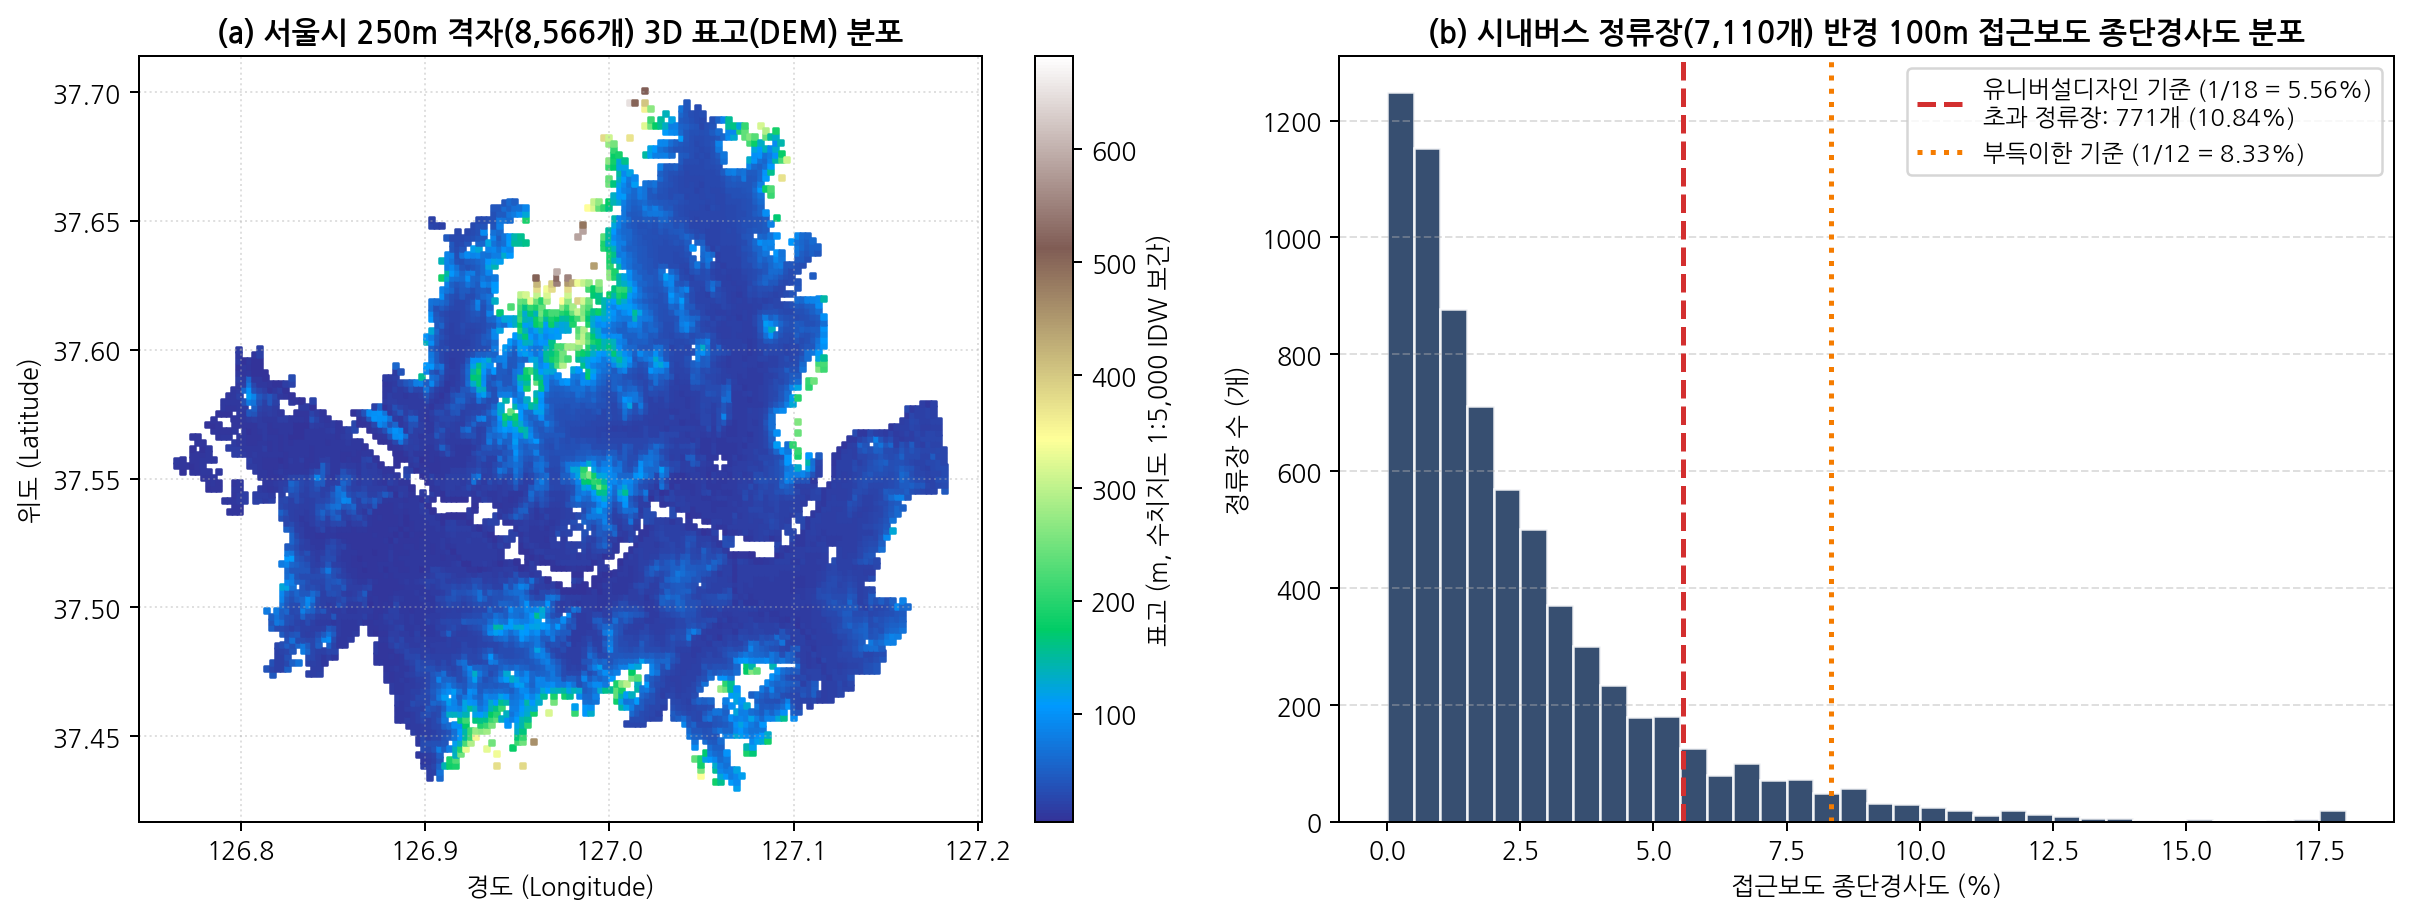

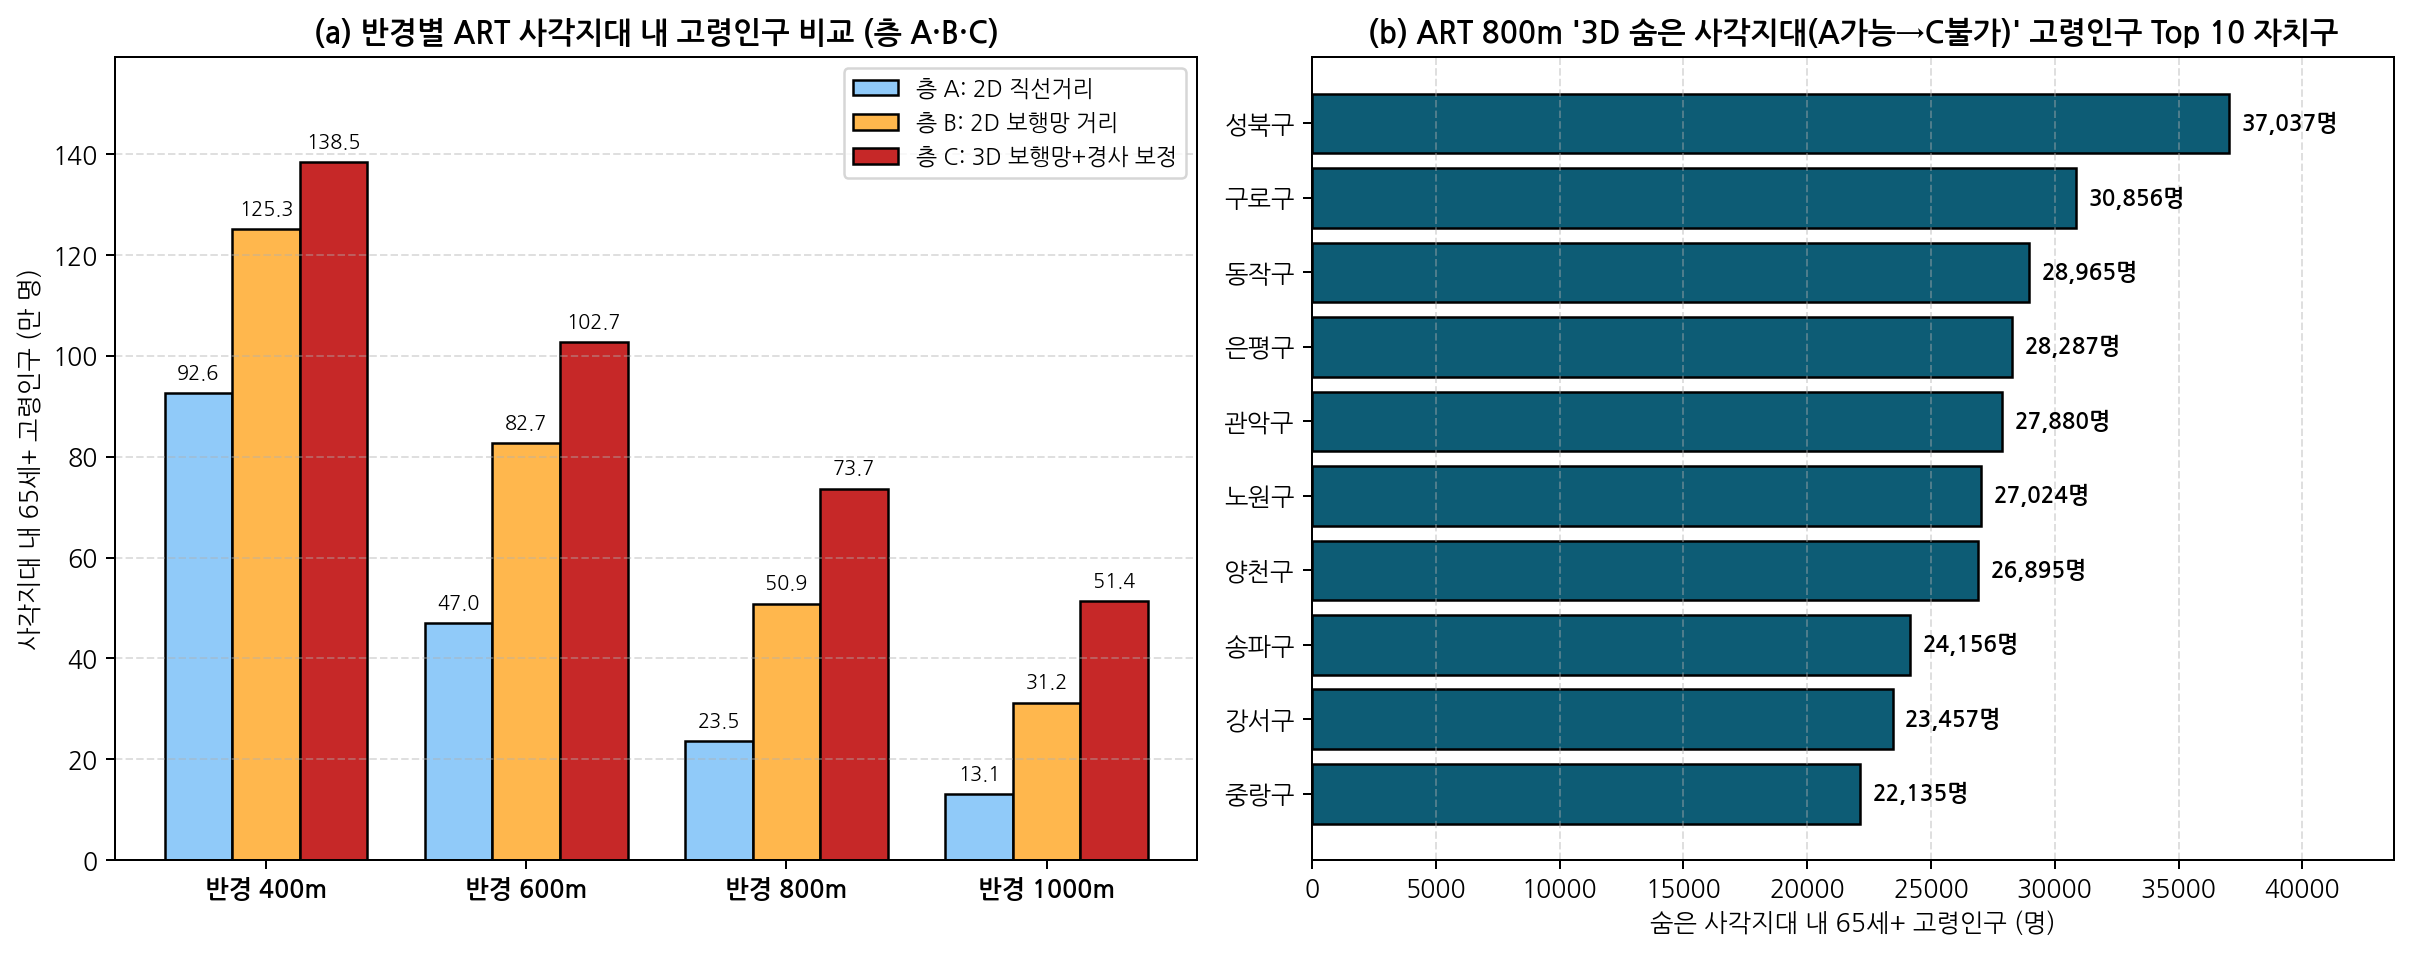

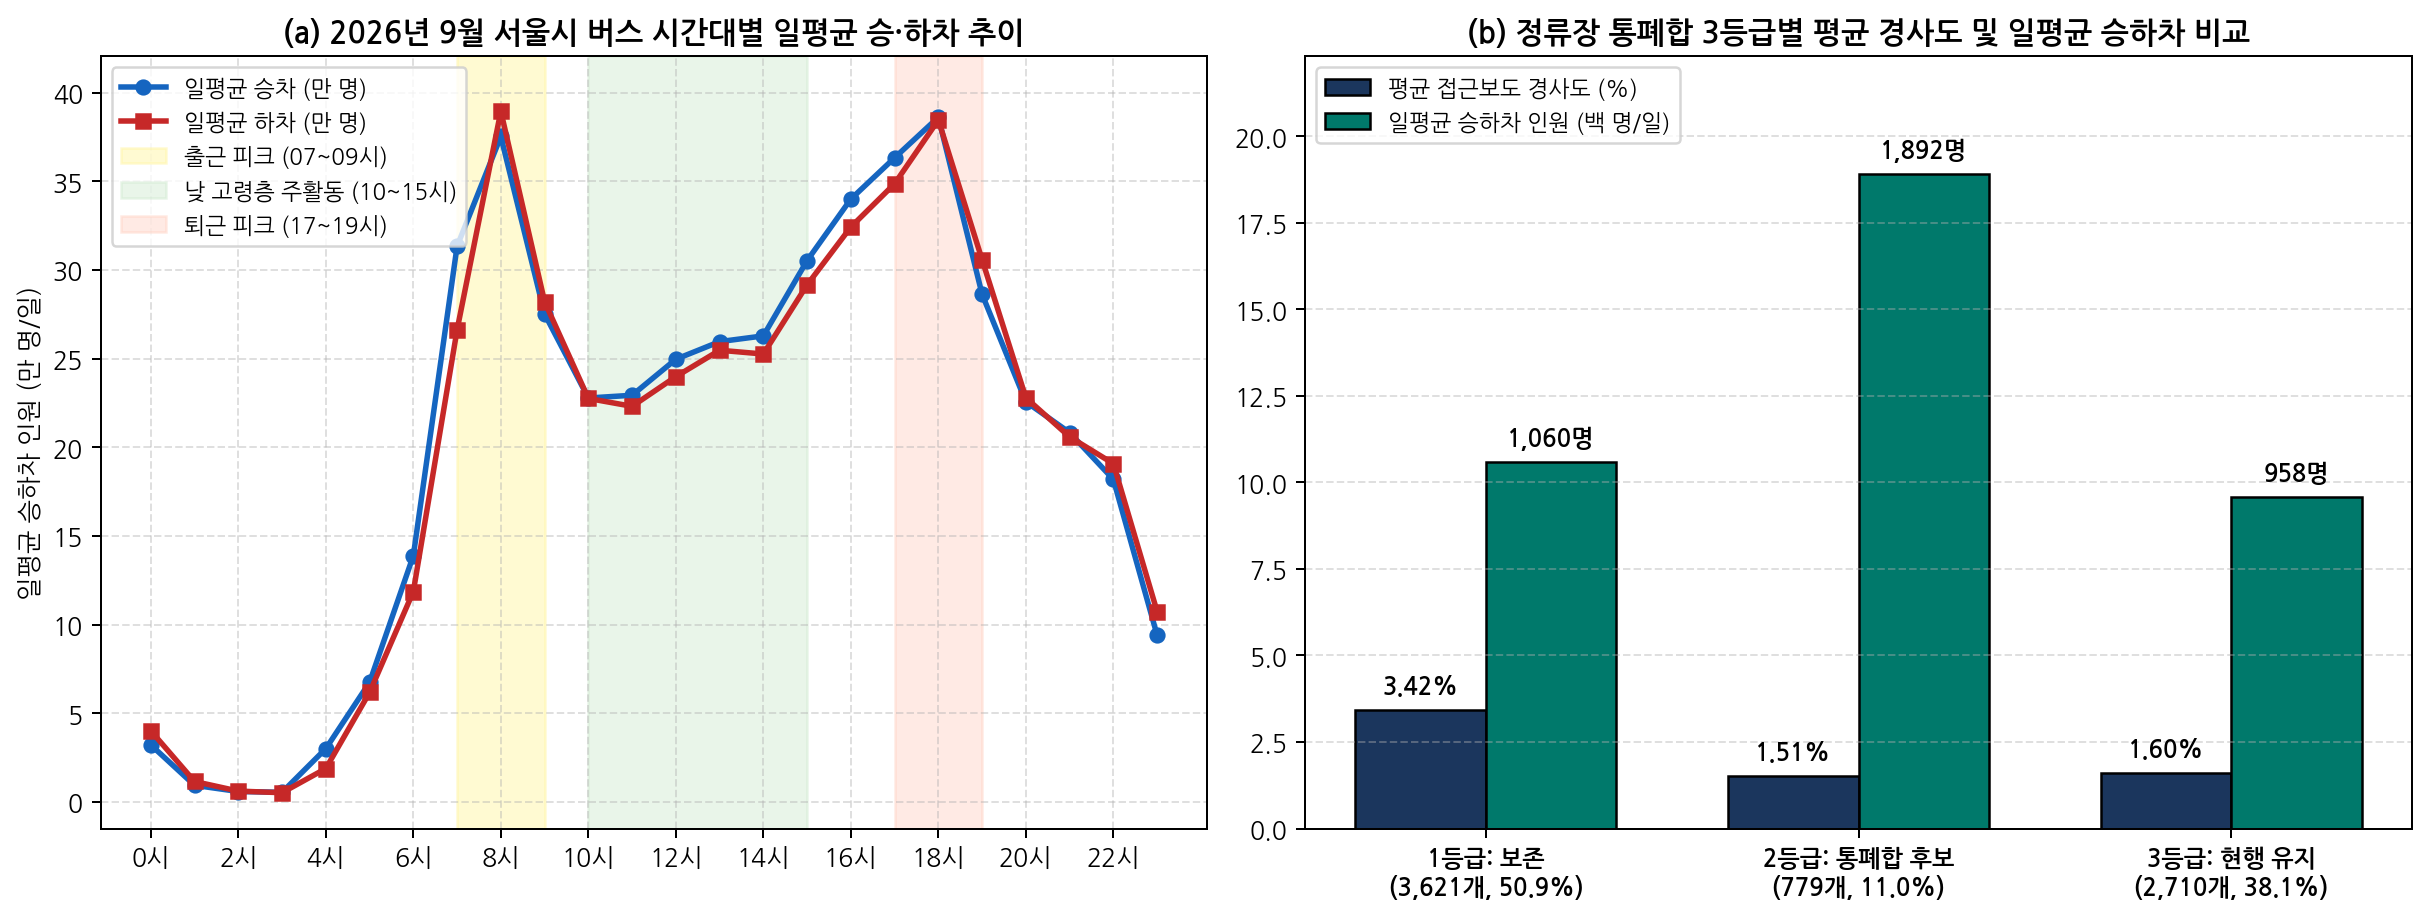

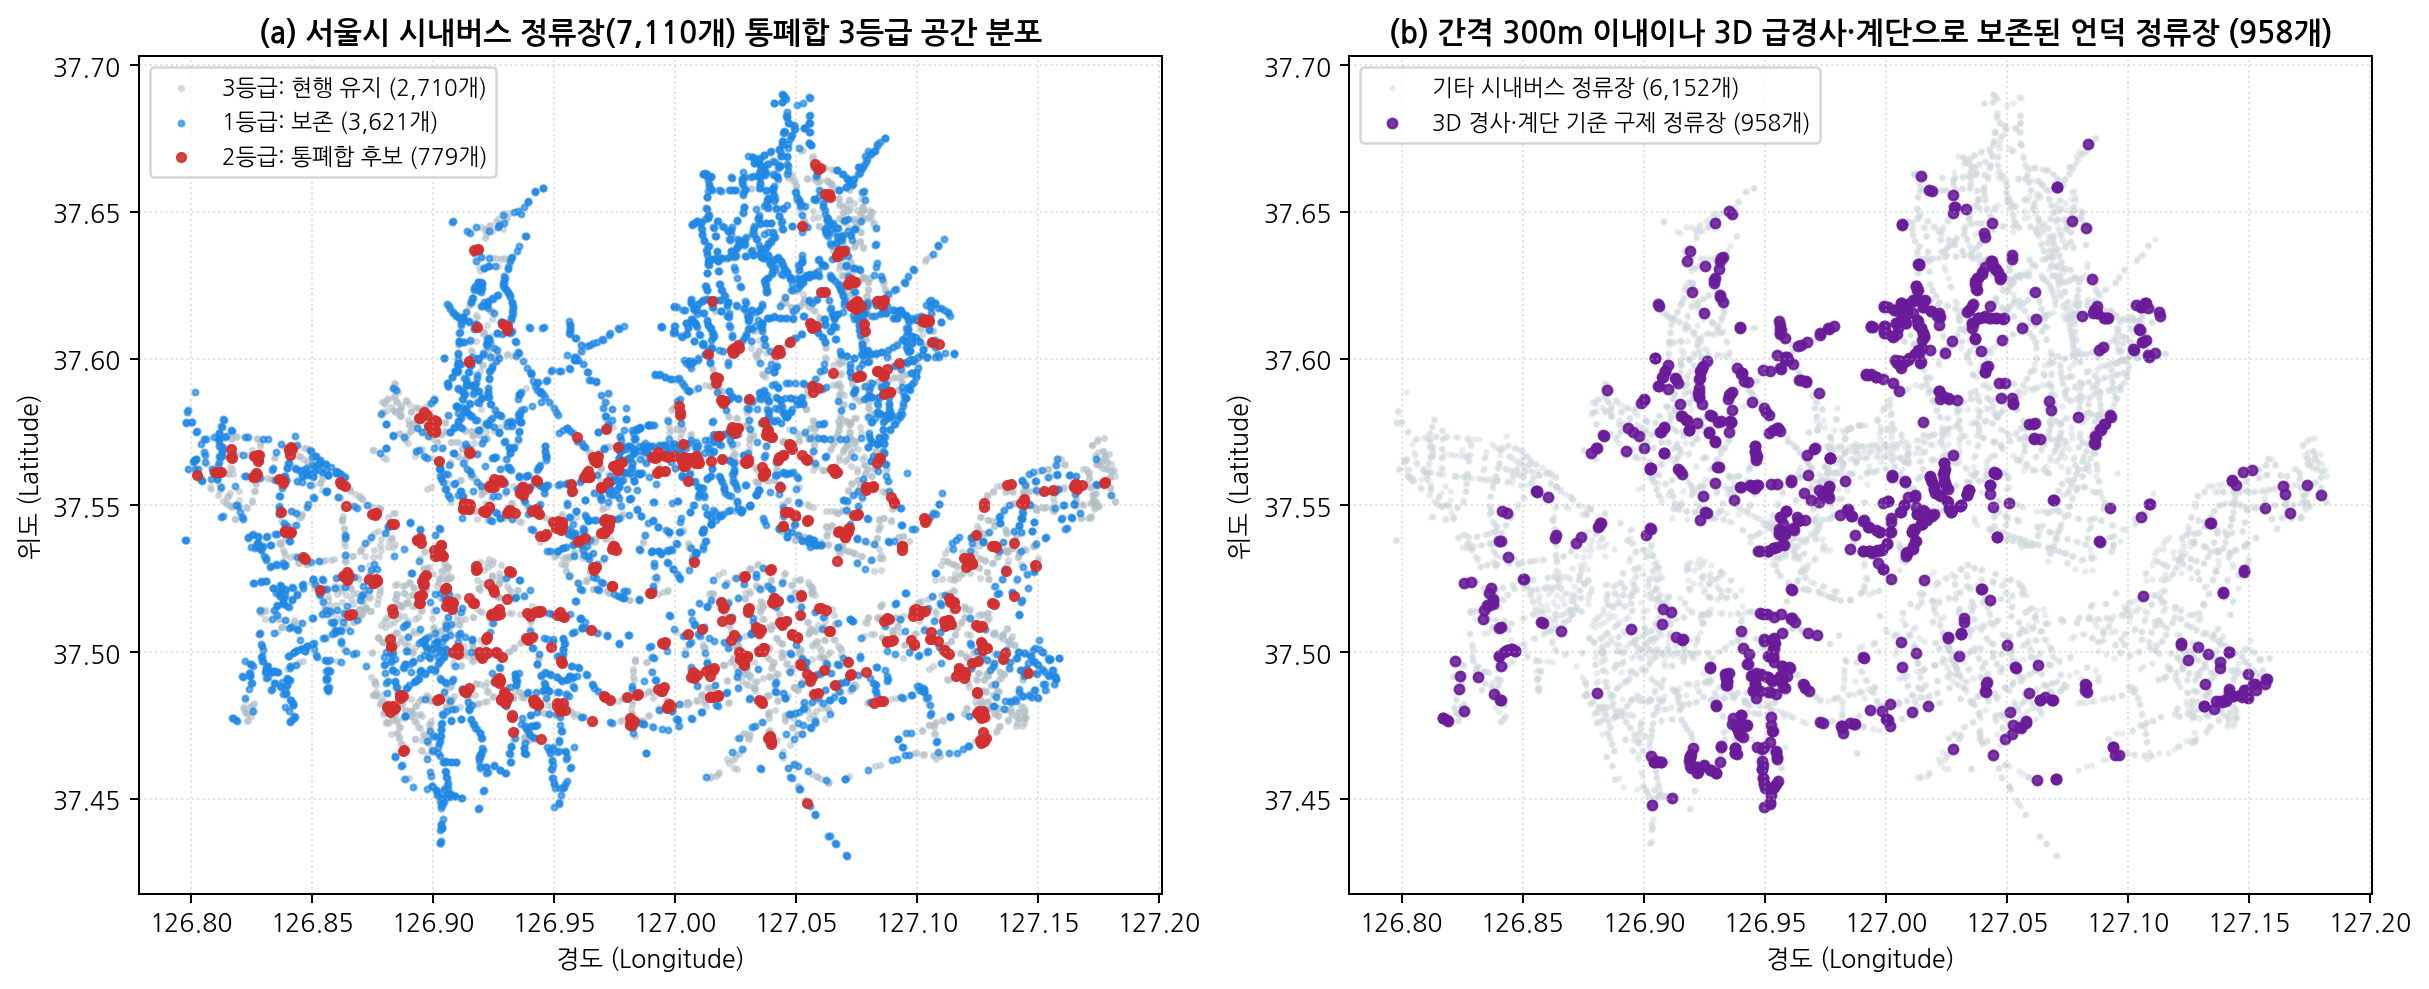


🎉 전 과정 분석·통계검정·시각화 완료! (총 소요시간: 50.3초)


In [15]:
# ==========================================================================
# [보고서 9장] 핵심 시각화 도표 (그림 2, 그림 4, 그림 7, 그림 8) 일괄 출력 및 저장
# ==========================================================================
print("\n" + "=" * 90)
print("🎨 [보고서 9장] 핵심 분석결과 시각화 이미지 생성 및 PNG 저장 중...")
print("=" * 90)

# 1) 보고서 그림 2 (250m 격자 3D 표고 분포 & 정류장 접근보도 종단경사도 분포)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180)
sc = axes[0].scatter(grid_df["경도"], grid_df["위도"], c=grid_df["표고_m"], cmap="terrain", s=4, marker="s")
cb = plt.colorbar(sc, ax=axes[0])
cb.set_label("표고 (m, 수치지도 1:5,000 IDW 보간)")
axes[0].set_title(f"(a) 서울시 250m 격자({len(grid_df):,}개) 3D 표고(DEM) 분포", fontsize=12, fontweight="bold")
axes[0].set_xlabel("경도 (Longitude)")
axes[0].set_ylabel("위도 (Latitude)")
axes[0].grid(True, linestyle=":", alpha=0.4)

slope_clipped = np.clip(bus_city["접근보도_경사도_pct"], 0, 18)
over_556_cnt = int((bus_city["접근보도_경사도_pct"] >= 5.56).sum())
over_556_pct = over_556_cnt / len(bus_city) * 100.0
axes[1].hist(slope_clipped, bins=36, color="#1B365D", edgecolor="white", alpha=0.88)
axes[1].axvline(5.56, color="#D32F2F", linestyle="--", linewidth=2.0,
                label=f"유니버설디자인 기준 (1/18 = 5.56%)\n초과 정류장: {over_556_cnt:,}개 ({over_556_pct:.2f}%)")
axes[1].axvline(8.33, color="#F57C00", linestyle=":", linewidth=2.0,
                label="부득이한 기준 (1/12 = 8.33%)")
axes[1].set_title(f"(b) 시내버스 정류장({len(bus_city):,}개) 반경 100m 접근보도 종단경사도 분포", fontsize=12, fontweight="bold")
axes[1].set_xlabel("접근보도 종단경사도 (%)")
axes[1].set_ylabel("정류장 수 (개)")
axes[1].legend(loc="upper right", fontsize=9.5, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_dem_slope_dist.png"), bbox_inches="tight", dpi=180)
plt.show()

# 2) 보고서 그림 4 (반경별 ART 사각지대 내 고령인구 비교 & 3D 숨은 사각지대 Top 10 자치구)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), dpi=180)
radii = [400, 600, 800, 1000]
sen_a = [grid_df[grid_df["dist_art_2d_m"] > r]["격자_추정_주민고령인구"].sum() / 10000 for r in radii]
sen_b = [grid_df[grid_df["dist_art_walk_2d_m"] > r]["격자_추정_주민고령인구"].sum() / 10000 for r in radii]
sen_c = [grid_df[grid_df["dist_art_3d_tobler_m"] > r]["격자_추정_주민고령인구"].sum() / 10000 for r in radii]
x = np.arange(len(radii))
w = 0.26
b1 = axes[0].bar(x - w, sen_a, width=w, color="#90CAF9", edgecolor="black", label="층 A: 2D 직선거리")
b2 = axes[0].bar(x, sen_b, width=w, color="#FFB74D", edgecolor="black", label="층 B: 2D 보행망 거리")
b3 = axes[0].bar(x + w, sen_c, width=w, color="#C62828", edgecolor="black", label="층 C: 3D 보행망+경사 보정")
for bars in [b1, b2, b3]:
    for bar in bars:
        h_val = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width() / 2, h_val + 2, f"{h_val:.1f}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"반경 {r}m" for r in radii], fontweight="bold")
axes[0].set_ylabel("사각지대 내 65세+ 고령인구 (만 명)")
axes[0].set_title("(a) 반경별 ART 사각지대 내 고령인구 비교 (층 A·B·C)", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, max(sen_c) * 1.15)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

gu_top10 = gu_summary.head(10).iloc[::-1]
axes[1].barh(gu_top10["시군구명"], gu_top10["숨은사각_고령인구"], color="#0D5C75", edgecolor="black")
axes[1].set_title("(b) ART 800m '3D 숨은 사각지대(A가능→C불가)' 고령인구 Top 10 자치구", fontsize=12, fontweight="bold")
axes[1].set_xlabel("숨은 사각지대 내 65세+ 고령인구 (명)")
for i, v in enumerate(gu_top10["숨은사각_고령인구"]):
    axes[1].text(v + 500, i, f"{v:,.0f}명", va="center", fontsize=9, fontweight="bold")
axes[1].set_xlim(0, gu_top10["숨은사각_고령인구"].max() * 1.18)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig4_art_blindspot_3d.png"), bbox_inches="tight", dpi=180)
plt.show()

# 3) 보고서 그림 7 (2026년 9월 시간대별 일평균 승·하차 추이 & 3등급별 평균 경사도·승하차 비교)
hours = np.arange(24)
if rid_raw is not None:
    board_cols = [f"{h:02d}시승차총승객수" if (f"{h:02d}시승차총승객수" in rid_raw.columns) else f"{h}시승차총승객수" for h in range(24)]
    alight_cols = [f"{h:02d}시하차총승객수" if (f"{h:02d}시하차총승객수" in rid_raw.columns) else f"{h}시하차총승객수" for h in range(24)]
    hourly_board_man = np.array([rid_raw[c].sum() / 30.0 / 10000.0 for c in board_cols])
    hourly_alight_man = np.array([rid_raw[c].sum() / 30.0 / 10000.0 for c in alight_cols])
else:
    hourly_board_man = np.array([3.2, 0.9, 0.5, 0.5, 3.0, 6.7, 13.8, 31.3, 37.6, 27.5, 22.7, 22.9, 24.9, 26.0, 26.2, 30.5, 34.0, 36.4, 38.6, 28.7, 22.5, 20.8, 18.2, 9.4])
    hourly_alight_man = np.array([4.0, 1.1, 0.6, 0.4, 1.8, 6.0, 11.8, 26.5, 38.9, 28.1, 22.7, 22.3, 23.9, 25.4, 25.2, 29.1, 32.4, 34.9, 38.4, 30.6, 22.8, 20.5, 19.0, 10.7])

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.2), dpi=180)
axes[0].plot(hours, hourly_board_man, marker="o", color="#1565C0", linewidth=2.2, markersize=5.5, label="일평균 승차 (만 명)")
axes[0].plot(hours, hourly_alight_man, marker="s", color="#C62828", linewidth=2.2, markersize=5.5, label="일평균 하차 (만 명)")
axes[0].axvspan(7, 9, color="#FFF59D", alpha=0.45, label="출근 피크 (07~09시)")
axes[0].axvspan(10, 15, color="#C8E6C9", alpha=0.40, label="낮 고령층 주활동 (10~15시)")
axes[0].axvspan(17, 19, color="#FFCCBC", alpha=0.40, label="퇴근 피크 (17~19시)")
axes[0].set_title("(a) 2026년 9월 서울시 버스 시간대별 일평균 승·하차 추이", fontsize=12, fontweight="bold")
axes[0].set_ylabel("일평균 승하차 인원 (만 명/일)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xticklabels([f"{h}시" for h in range(0, 24, 2)])
axes[0].set_ylim(-1.5, max(hourly_board_man.max(), hourly_alight_man.max()) * 1.08)
axes[0].legend(loc="upper left", fontsize=9, frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.4)

grade_order = [
    ("1등급: 보존", bus_city["통폐합_3등급_3D"].str.startswith("1등급")),
    ("2등급: 통폐합 후보", bus_city["통폐합_3등급_3D"].str.startswith("2등급")),
    ("3등급: 현행 유지", bus_city["통폐합_3등급_3D"].str.startswith("3등급")),
]
x_labels, mean_slopes, mean_rid_hundreds, mean_rid_persons = [], [], [], []
for short_title, mask in grade_order:
    sub = bus_city[mask]
    cnt = len(sub)
    pct = cnt / len(bus_city) * 100.0
    x_labels.append(f"{short_title}\n({cnt:,}개, {pct:.1f}%)")
    slp = sub["접근보도_경사도_pct"].mean()
    rid_p = sub["일평균_승하차인원"].mean()
    mean_slopes.append(slp)
    mean_rid_persons.append(rid_p)
    mean_rid_hundreds.append(rid_p / 100.0)

x_pos = np.arange(3)
bar_w = 0.35
bars_slope = axes[1].bar(x_pos - bar_w / 2, mean_slopes, width=bar_w, color="#1B365D", edgecolor="black", label="평균 접근보도 경사도 (%)")
bars_rid = axes[1].bar(x_pos + bar_w / 2, mean_rid_hundreds, width=bar_w, color="#00796B", edgecolor="black", label="일평균 승하차 인원 (백 명/일)")
for b, val in zip(bars_slope, mean_slopes):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.35, f"{val:.2f}%", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
for b, p_val in zip(bars_rid, mean_rid_persons):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.35, f"{p_val:,.0f}명", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axes[1].set_title("(b) 정류장 통폐합 3등급별 평균 경사도 및 일평균 승하차 비교", fontsize=12, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, fontsize=9.5, fontweight="bold")
axes[1].set_ylim(0, max(max(mean_rid_hundreds), max(mean_slopes)) * 1.18)
axes[1].legend(loc="upper left", fontsize=9, frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig7_hourly_ridership_and_3grade_bars.png"), bbox_inches="tight", dpi=180)
plt.show()

# 4) 보고서 그림 8 (시내버스 정류장 3등급 공간 분포 & 3D 급경사·계단 구제 언덕 정류장 958개)
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.6), dpi=180)
plot_layers = [
    ("3등급: 현행 유지", bus_city["통폐합_3등급_3D"].str.startswith("3등급"), "#B0BEC5", 4, 0.45),
    ("1등급: 보존", bus_city["통폐합_3등급_3D"].str.startswith("1등급"), "#1E88E5", 5, 0.65),
    ("2등급: 통폐합 후보", bus_city["통폐합_3등급_3D"].str.startswith("2등급"), "#D32F2F", 12, 0.90),
]
for label_prefix, mask, c_hex, sz, alp in plot_layers:
    sub = bus_city[mask]
    axes[0].scatter(sub["경도"], sub["위도"], s=sz, c=c_hex, alpha=alp, label=f"{label_prefix} ({len(sub):,}개)")
axes[0].set_title(f"(a) 서울시 시내버스 정류장({len(bus_city):,}개) 통폐합 3등급 공간 분포", fontsize=12, fontweight="bold")
axes[0].set_xlabel("경도 (Longitude)")
axes[0].set_ylabel("위도 (Latitude)")
axes[0].legend(loc="upper left", fontsize=9, frameon=True)
axes[0].grid(True, linestyle=":", alpha=0.4)

axes[1].scatter(bus_city.loc[~saved_by_3d_mask, "경도"], bus_city.loc[~saved_by_3d_mask, "위도"],
                s=3, c="#CFD8DC", alpha=0.35, label=f"기타 시내버스 정류장 ({(~saved_by_3d_mask).sum():,}개)")
axes[1].scatter(bus_city.loc[saved_by_3d_mask, "경도"], bus_city.loc[saved_by_3d_mask, "위도"],
                s=14, c="#6A1B9A", alpha=0.88, label=f"3D 경사·계단 기준 구제 정류장 ({saved_by_3d_cnt:,}개)")
axes[1].set_title(f"(b) 간격 300m 이내이나 3D 급경사·계단으로 보존된 언덕 정류장 ({saved_by_3d_cnt:,}개)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("경도 (Longitude)")
axes[1].set_ylabel("위도 (Latitude)")
axes[1].legend(loc="upper left", fontsize=9, frameon=True)
axes[1].grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig8_bus_stop_3grade_and_saved958_map.png"), bbox_inches="tight", dpi=180)
plt.show()

print(f"\n🎉 전 과정 분석·통계검정·시각화 완료! (총 소요시간: {time.time()-t0:.1f}초)")